# The Eilers-Marx backend: the mathematics, and the workflow

This is the companion to `examples/wood_backend_math_tutorial.ipynb`. Where the
Wood backend bets on **richness and automatic inference** (nine bases, continuous
REML optimisation, F-tests), the Eilers-Marx backend (`backend='eilers'`) bets on
**doing one thing well**:

1. **One basis family.** Every smooth is a *uniform cubic B-spline* with
   `n_splines = K` coefficients.
2. **One penalty family.** Smoothness is charged by a *second-order difference*
   penalty `P = lambda * D2^T D2`, with circular and ridge variants and an
   active-set extension for shape constraints.
3. **One criterion, evaluated honestly.** `lambda` — and optionally `K` — is
   chosen by scanning a finite, user-visible grid with the Generalised Cross
   Validation (GCV) score. No derivatives, no optimiser, no surprises.

Same target, different philosophy. The payoff is speed, transparency and
**soft shape constraints** (`mono_inc`, `mono_dec`, `convex`, `concave`,
`periodic`) that no other backend in `magli` provides.

**How to read this notebook.** Every formula is followed by code that checks it.
Cells marked *Check* end in `assert` statements, so a clean top-to-bottom run
means the mathematics in the markdown matched the library numerically. The last
cell prints a pass/fail audit of the headline invariants.

Prerequisites: linear algebra (QR, SVD, Cholesky), basic statistics (least
squares, cross-validation), and Parts I-III of the Wood notebook (or any GAM
introduction). Companion material: `docs/math/eilers.rst`, `docs/constraints.rst`
and `docs/gridsearch.rst` in the repository, plus Eilers & Marx (1996) and
Wood (2017) for the underlying theory.

## 0. Setup

We use the public dispatcher (`GAM`/`LinGAM`/`GAMCore` with `backend='eilers'`)
and, for the derivations, the low-level pieces of the backend:

| import | what it does |
|---|---|
| `b_spline_basis` | the vectorised De Boor recursion (Part II) |
| `second_diff_penalty`, `circular_second_diff_penalty`, `ridge_penalty` | penalty builders (Part III) |
| `shape_constraint_penalty` | the active-set penalty `C(beta)` (Part III) |
| `solve_pirls` | the SVD data-augmentation solver (Part IV) |

In [1]:
%matplotlib inline

import time

import numpy as np
import matplotlib.pyplot as plt

import magli
from magli import GAM, LinGAM, GAMCore
from magli.eilers import LinGAM as EilersLinGAM
from magli.eilers._bspline import b_spline_basis
from magli.eilers._penalty import (
    circular_second_diff_penalty,
    ridge_penalty,
    second_diff_penalty,
    shape_constraint_penalty,
)
from magli.eilers._solver import solve_pirls
from magli.wood import LinGAM as WoodLinGAM
from scipy import stats

np.set_printoptions(precision=4, suppress=True)

print("magli", magli.__version__)
print("backends:", magli.eilers.__name__, "+", magli.wood.__name__)
print("numpy", np.__version__)

magli 1.0.0
backends: magli.eilers + magli.wood
numpy 2.5.2


---
# Part I. The model, the dial, and the trap

The model is the familiar additive one,

$$y_i = \beta_0 + \sum_{j=1}^{J} f_j(\mathbf{x}_i) + \varepsilon_i,
\qquad \varepsilon_i \sim N(0, \sigma^2),$$

and each smooth is written in a fixed, uniform B-spline basis with $K_j$
columns, $f_j(x) = \sum_{m} \beta_{jm} B_m(x)$. Fitting minimises

$$\underbrace{\|\mathbf{y} - X\boldsymbol{\beta}\|^2}_{\text{fit}}
\;+\;
\underbrace{\boldsymbol{\beta}^\top P\, \boldsymbol{\beta}}_{\text{wiggliness tax}},
\qquad
P = \lambda\, D_2^\top D_2,$$

where $D_2$ differences *adjacent coefficients*: the discrete stand-in for
curvature. Everything else in this notebook is about the details of that
sentence — and about the one number, $\lambda$, that you have to get right.

**The trap.** `fit()` does **not** choose $\lambda$. It uses the `lam` stored on
the term (default `1.0`). Choosing $\lambda$ is the job of `gridsearch()`. The
next three cells show why that distinction matters.

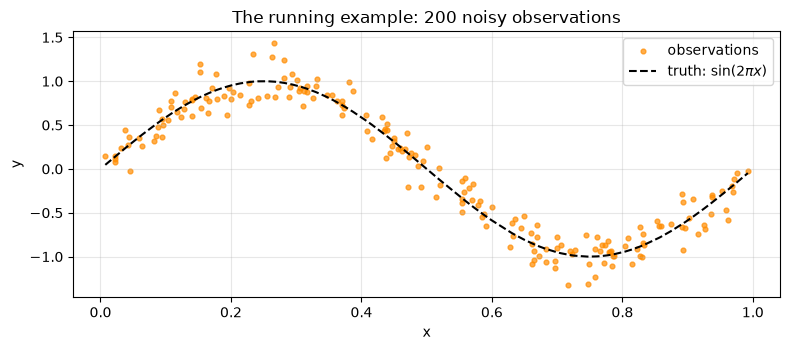

expected RSS at the truth: 4.5


In [2]:
# The running example, reused from the Wood notebook so the two can be compared:
#   y = sin(2 pi x) + noise,  x in [0, 1]
rng = np.random.default_rng(42)
n = 200
x = np.sort(rng.uniform(0.0, 1.0, n))
f_true = np.sin(2 * np.pi * x)
y = f_true + rng.normal(0.0, 0.15, n)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(x, y, s=12, color="darkorange", alpha=0.7, label="observations")
ax.plot(x, f_true, "k--", lw=1.5, label=r"truth: $\sin(2\pi x)$")
ax.set(xlabel="x", ylabel="y", title="The running example: 200 noisy observations")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("expected RSS at the truth:", round(n * 0.15**2, 2))

### The dial

Hold $\lambda$ fixed and turn it by hand (`LinGAM(n_splines=K, lam=...)`). Two
things move at once: the shape of the curve, and the effective degrees of
freedom. As $\lambda \to 0$ the curve chases the data and EDF climbs to $K$ (the
number of basis coefficients); as $\lambda \to \infty$ only the penalty's null
space survives — constants and straight lines — so the fitted term becomes
linear and the *model* EDF floors at 2 (intercept + one slope).

The floor is a general fact worth memorising: **a second-difference penalty
cannot remove a term, only straighten it.** Removing terms is what the `ts`/`cs`
bases in the Wood backend are for.

    lambda      EDF       RSS
     1e-06  11.9997    4.3366
     1e-03  11.7245    4.3387
     1e-01   8.9402    4.4663
     1e+00   6.6138    4.5677
     1e+01   4.5406    6.3782
     1e+03   2.2570   36.4877
     1e+06   2.0003   38.6955


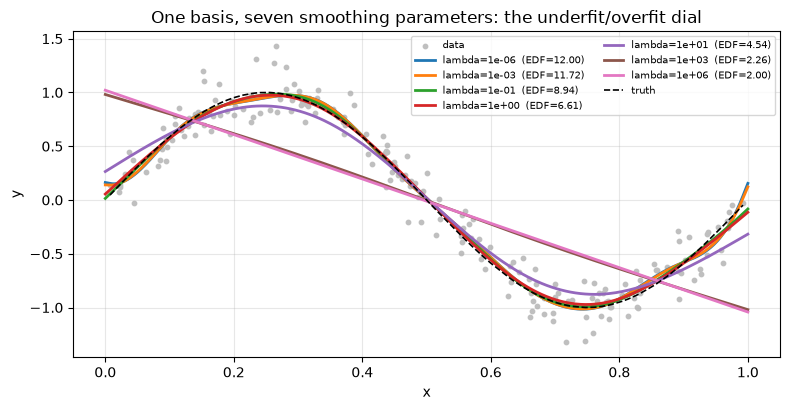

In [3]:
lambdas = [1e-6, 1e-3, 1e-1, 1e0, 1e1, 1e3, 1e6]
x_grid = np.linspace(0, 1, 400)

rows, curves = [], []
for lam in lambdas:
    m = LinGAM(n_splines=12, lam=lam, backend="eilers").fit(x, y)
    rows.append((lam, m.statistics_["edof"], m.statistics_["rss"]))
    curves.append(m.predict(x_grid))

print(f"{'lambda':>10} {'EDF':>8} {'RSS':>9}")
for lam, edf, rss in rows:
    print(f"{lam:10.0e} {edf:8.4f} {rss:9.4f}")

edfs = [r[1] for r in rows]
assert edfs[0] > edfs[-1], "EDF must shrink as lambda grows"
assert edfs[0] > 11.9, "with almost no penalty the smooth uses all K = 12 coefficients"
assert abs(edfs[-1] - 2.0) < 0.05, "with an enormous penalty: intercept + straight line = 2"

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(x, y, s=10, color="0.75", label="data")
for lam, curve in zip(lambdas, curves):
    edf = [r[1] for r in rows if r[0] == lam][0]
    ax.plot(x_grid, curve, lw=2, label=f"lambda={lam:.0e}  (EDF={edf:.2f})")
ax.plot(x, f_true, "k--", lw=1.2, label="truth")
ax.set(xlabel="x", ylabel="y", title="One basis, seven smoothing parameters: the underfit/overfit dial")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fit(lam=1.0) : lam=        1  EDF= 15.52  GCV= 0.010115  RMSE=0.0585
gridsearch() : lam=      0.1  EDF= 22.23  GCV= 0.006839  RMSE=0.0227


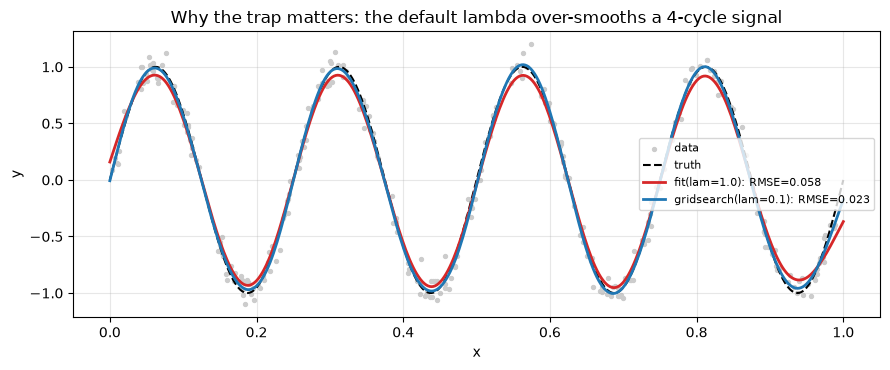

In [4]:
# --- the trap: fit() uses the stored lam; only gridsearch() tunes it ---------
rng_sharp = np.random.default_rng(2)
n_sharp = 300
x_sharp = np.sort(rng_sharp.uniform(0.0, 1.0, n_sharp))
truth_sharp = np.sin(2 * np.pi * 4 * x_sharp)     # four cycles: needs a small lambda
y_sharp = truth_sharp + rng_sharp.normal(0.0, 0.08, n_sharp)

m_fixed = LinGAM(n_splines=30, lam=1.0, backend="eilers").fit(x_sharp, y_sharp)
m_tuned = LinGAM(n_splines=30, backend="eilers").gridsearch(x_sharp, y_sharp, lam=np.logspace(-8, 1, 19))

rmse = lambda m: float(np.sqrt(np.mean((m.predict(x_sharp) - truth_sharp) ** 2)))
print(f"fit(lam=1.0) : lam={m_fixed.lam:9.4g}  EDF={m_fixed.statistics_['edof']:6.2f}  "
      f"GCV={m_fixed.statistics_['GCV']:9.6f}  RMSE={rmse(m_fixed):.4f}")
print(f"gridsearch() : lam={m_tuned.lam:9.4g}  EDF={m_tuned.statistics_['edof']:6.2f}  "
      f"GCV={m_tuned.statistics_['GCV']:9.6f}  RMSE={rmse(m_tuned):.4f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(x_sharp, y_sharp, s=8, color="0.8", label="data")
ax.plot(x_grid, np.sin(2 * np.pi * 4 * x_grid), "k--", lw=1.5, label="truth")
ax.plot(x_grid, m_fixed.predict(x_grid), "C3-", lw=2, label=f"fit(lam=1.0): RMSE={rmse(m_fixed):.3f}")
ax.plot(x_grid, m_tuned.predict(x_grid), "C0-", lw=2, label=f"gridsearch(lam={m_tuned.lam:g}): RMSE={rmse(m_tuned):.3f}")
ax.set(xlabel="x", ylabel="y", title="Why the trap matters: the default lambda over-smooths a 4-cycle signal")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert m_tuned.lam < m_fixed.lam
assert rmse(m_tuned) < 0.6 * rmse(m_fixed), "the tuned fit must be clearly better here"

---
# Part II. Uniform B-splines

**Why not use a high-degree polynomial?** A degree-15 polynomial can wiggle, but
every data point influences the curve *everywhere*: the coefficients are globally
coupled and the fit oscillates wildly near the edges (Runge's phenomenon). The
B-spline trick is to build the curve from *local* pieces:

$$f(x) = \sum_{j=1}^{K} \beta_j B_j(x),$$

where each $B_j$ is a smooth bump of compact support. Moving one coefficient
changes the curve only locally, and the basis is numerically benign. The cell
below puts the two side by side on the same 30 noisy points.

degree-15 polynomial: max deviation from the truth =   369.67
B-spline, K = 12     : max deviation from the truth =    0.085


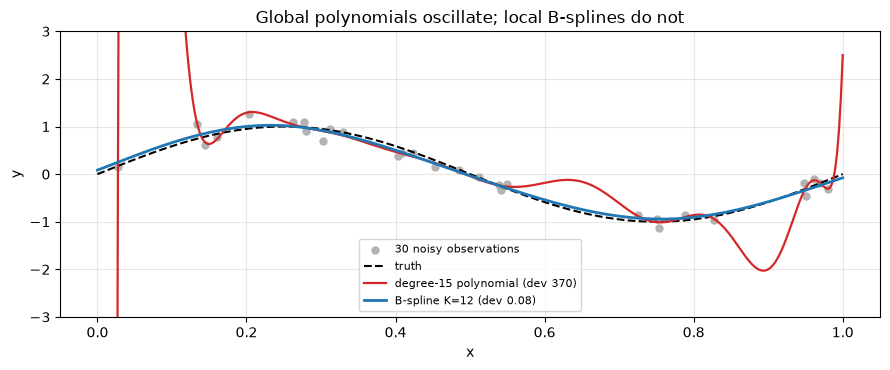

In [5]:
rng_runge = np.random.default_rng(1)
x_small = np.sort(rng_runge.uniform(0.0, 1.0, 30))
y_small = np.sin(2 * np.pi * x_small) + rng_runge.normal(0.0, 0.15, 30)

poly15 = np.poly1d(np.polyfit(x_small, y_small, 15))
spline = LinGAM(n_splines=12, backend="eilers").gridsearch(x_small, y_small)

dev_poly = float(np.max(np.abs(poly15(x_grid) - np.sin(2 * np.pi * x_grid))))
dev_spline = float(np.max(np.abs(spline.predict(x_grid) - np.sin(2 * np.pi * x_grid))))
print(f"degree-15 polynomial: max deviation from the truth = {dev_poly:8.2f}")
print(f"B-spline, K = 12     : max deviation from the truth = {dev_spline:8.3f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(x_small, y_small, s=25, color="0.7", label="30 noisy observations")
ax.plot(x_grid, np.sin(2 * np.pi * x_grid), "k--", lw=1.5, label="truth")
ax.plot(x_grid, poly15(x_grid), "C3-", lw=1.6, label=f"degree-15 polynomial (dev {dev_poly:.0f})")
ax.plot(x_grid, spline.predict(x_grid), "C0-", lw=2, label=f"B-spline K=12 (dev {dev_spline:.2f})")
ax.set(ylim=(-3, 3), xlabel="x", ylabel="y", title="Global polynomials oscillate; local B-splines do not")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert dev_poly > 10.0, "the polynomial must blow up outside the data"
assert dev_spline < 0.5, "the spline stays close to the truth"

### The Cox-de Boor recursion

Map the data to $[0,1]$ and place **uniform** knots: $1 + K - k$ boundary knots
divide the interval into $K-k$ spans. Augment the knot sequence with $k$ extra
knots beyond each end, then build the basis recursively, starting from the
piecewise-constant functions

$$B_{i,1}(z) = \mathbf{1}_{[\tau_i, \tau_{i+1})}(z),
\qquad
B_{i,m}(z)
= \frac{z - \tau_i}{\tau_{i+m-1} - \tau_i} B_{i,m-1}(z)
+ \frac{\tau_{i+m} - z}{\tau_{i+m} - \tau_{i+1}} B_{i+1,m-1}(z).$$

Each recursion step raises the polynomial order by one and drops one function, so
$K$ functions of order $k+1$ remain. Two consequences matter in practice:

* **Partition of unity**: $\sum_j B_j(z) = 1$ for every $z$, so the basis always
  contains the constant function — the reason the intercept column is redundant
  (Part IV) and why an added constant cannot be told apart from the basis.
* **Compact support**: $B_j$ is non-zero on $k+1$ spans, so each coefficient
  controls a local patch.

`magli` defaults to `spline_order=3`, i.e. cubics: the lowest degree with
continuous second derivatives, which is what makes the curve look smooth.

**Extrapolation.** Outside the data range the basis is replaced by the *linear
extension* of the boundary value using the analytic boundary derivative,

$$f(z) \approx f(0) + f'(0)\,z \ (z<0), \qquad
  f(z) \approx f(1) + f'(1)\,(z-1) \ (z>1),$$

so predictions beyond the data follow the tangent rather than oscillating.

**Periodicity.** With `constraint='periodic'` the covariate is taken modulo the
(endpoint-normalised) range and the last $k$ basis columns are folded into the
first $k$, preserving the partition of unity, forcing $f(a) = f(b)$, and reducing
the coefficient count to $K_{\text{eff}} = K - k$.

max |hand-written recursion - library| = 0.0
partition of unity: max |sum_j B_j(x) - 1| = 2.220446049250313e-16
fraction of zeros per basis column: [0.89  0.775 0.65  0.56  0.56  0.565 0.565 0.55 ] (compact support)
second differences in the extrapolation regions: 6.7e-16 (left), 4.0e-15 (right)


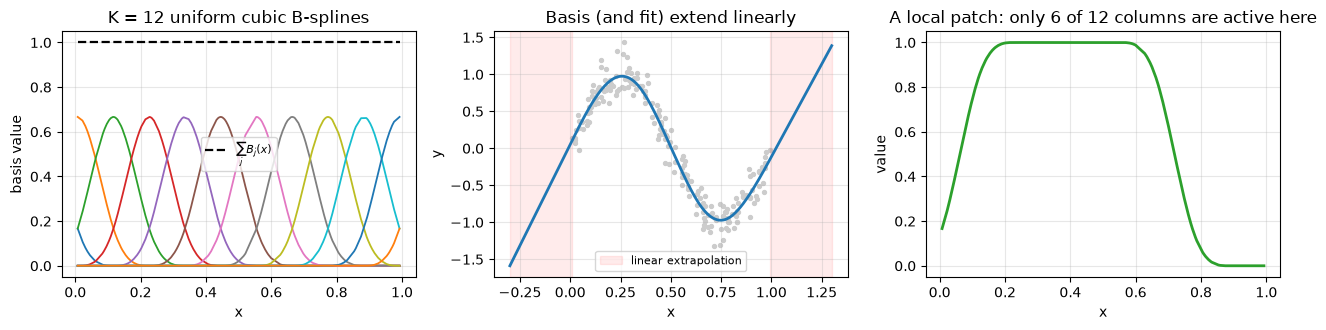

In [6]:
# --- a hand-written Cox-de Boor recursion, checked against the library -------
def cox_de_boor(z, K, k, lo, hi):
    # uniform B-spline basis, exactly the recursion written in the text above
    t = (np.asarray(z, float) - lo) / (hi - lo)
    knots = np.linspace(0.0, 1.0, 1 + K - k)
    d = knots[1] - knots[0]
    aug = np.r_[-np.arange(1, k + 1)[::-1] * d, knots, 1.0 + np.arange(1, k + 1) * d]
    aug[-1] += 1e-9
    B = ((t[:, None] >= aug[:-1][None, :]) & (t[:, None] < aug[1:][None, :])).astype(float)
    for m in range(2, k + 2):
        ncol = B.shape[1] - 1
        left = (t[:, None] - aug[:ncol][None, :]) * B[:, :ncol] / (aug[m - 1:ncol + m - 1] - aug[:ncol])[None, :]
        right = (aug[m:ncol + m][None, :] - t[:, None]) * B[:, 1:ncol + 1] / (aug[m:ncol + m] - aug[1:ncol + 1])[None, :]
        B = left + right
    return B


K, k = 12, 3
mine = cox_de_boor(x, K, k, x.min(), x.max())
library = b_spline_basis(x, K, k, np.array([x.min(), x.max()]))
print("max |hand-written recursion - library| =", float(np.abs(mine - library).max()))

print("partition of unity: max |sum_j B_j(x) - 1| =", float(np.abs(library.sum(axis=1) - 1).max()))
support = np.mean(np.abs(library) < 1e-12, axis=0)
print("fraction of zeros per basis column:", np.round(support[:8], 3), "(compact support)")

# extrapolation is exactly linear
m_ext = LinGAM(n_splines=K, backend="eilers").gridsearch(x, y)
x_wide = np.linspace(-0.3, 1.3, 801)
pred_wide = m_ext.predict(x_wide)
left = x_wide < x.min()
right = x_wide > x.max()
d2_left = float(np.abs(np.diff(pred_wide[left], 2)).max())
d2_right = float(np.abs(np.diff(pred_wide[right], 2)).max())
print(f"second differences in the extrapolation regions: {d2_left:.1e} (left), {d2_right:.1e} (right)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for j in range(library.shape[1]):
    axes[0].plot(x, library[:, j], lw=1.3)
axes[0].plot(x, library.sum(axis=1), "k--", lw=1.6, label=r"$\sum_j B_j(x)$")
axes[0].set(xlabel="x", ylabel="basis value", title=f"K = {K} uniform cubic B-splines")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].scatter(x, y, s=8, color="0.8")
axes[1].plot(x_wide, pred_wide, "C0-", lw=2)
axes[1].axvspan(x_wide[0], x.min(), color="red", alpha=0.08)
axes[1].axvspan(x.max(), x_wide[-1], color="red", alpha=0.08, label="linear extrapolation")
axes[1].set(xlabel="x", ylabel="y", title="Basis (and fit) extend linearly")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
axes[2].plot(x, library[:, 2:8].sum(axis=1), "C2-", lw=2)
axes[2].set(xlabel="x", ylabel="value", title="A local patch: only 6 of 12 columns are active here")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert np.abs(mine - library).max() == 0.0, "the recursion in the text IS the code"
assert np.abs(library.sum(axis=1) - 1).max() < 1e-12
assert support[K // 2 - 1] > 0.5, "interior B-splines are non-zero on a small fraction of the range"
assert d2_left < 1e-9 and d2_right < 1e-9, "outside the knots the basis is linear"

order     EDF      RSS  max |2nd diff|
    1   9.652   4.4500         0.00953
    2   8.453   4.4539         0.00032
    3   7.568   4.5173         0.00031


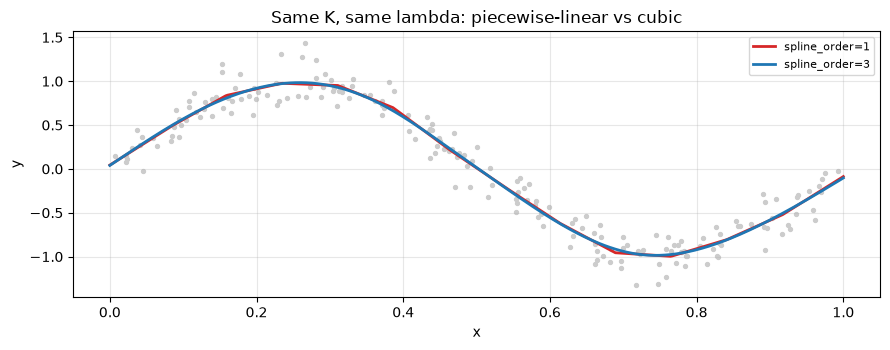

In [7]:
# --- what spline_order buys you ---------------------------------------------
print(f"{'order':>5} {'EDF':>7} {'RSS':>8} {'max |2nd diff|':>15}")
order_rows = []
for order in (1, 2, 3):
    m_ord = LinGAM(n_splines=14, lam=1.0, spline_order=order, backend="eilers").fit(x, y)
    d2 = float(np.abs(np.diff(m_ord.predict(x_grid), 2)).max())
    order_rows.append((order, m_ord.statistics_["edof"], m_ord.statistics_["rss"], d2))
    print(f"{order:5d} {m_ord.statistics_['edof']:7.3f} {m_ord.statistics_['rss']:8.4f} {d2:15.5f}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(x, y, s=8, color="0.8")
for order, color in ((1, "C3"), (3, "C0")):
    m_ord = LinGAM(n_splines=14, lam=1.0, spline_order=order, backend="eilers").fit(x, y)
    ax.plot(x_grid, m_ord.predict(x_grid), color, lw=2, label=f"spline_order={order}")
ax.set(xlabel="x", ylabel="y", title="Same K, same lambda: piecewise-linear vs cubic")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert order_rows[0][1] > order_rows[2][1], "piecewise-linear bases use more EDF at the same lambda"
assert order_rows[0][2] < order_rows[2][2], "and soak up more noise at the same penalty"

---
# Part III. The difference penalty

Eilers and Marx's insight is that the *coefficient sequence* carries the curve's
wiggliness: for a B-spline basis, the second difference $\Delta^2 \beta_j$ is a
discrete proxy for curvature. Charging its square gives

$$P = \lambda\, D_2^\top D_2,
\qquad
D_2 = \begin{pmatrix}
1 & -2 & 1 & & \\ & 1 & -2 & 1 & \\ & & \ddots & \ddots & \ddots
\end{pmatrix}_{(K-2)\times K},$$

with three properties that drive everything else:

* $P$ has **rank $K-2$**: its null space is spanned by the constant and linear
  coefficient sequences — the same "free shapes" idea as in the Wood backend, but
  built from differences instead of integrals.
* its **eigenvalues** are the price list of wiggliness: two zeros, then rapidly
  increasing costs for higher-frequency coefficient oscillations;
* it needs **no matrix inverse** (compare with `D^T B^{-1} D` for the cubic
  regression spline in the Wood notebook), which is why the Eilers-Marx engine is
  fast.

**Variants used by this backend**

| penalty | built by | used for |
|---|---|---|
| $\lambda D_2^\top D_2$ | `second_diff_penalty` | default smooths |
| circular $D_2^\top D_2$ (wrapping) | `circular_second_diff_penalty` | `constraint='periodic'` |
| $\lambda I$ | `ridge_penalty` | `f()` factor terms (and `l()` if penalised) |
| $\lambda_{\text{con}} D_m^\top \operatorname{diag}(v(\beta)) D_m + \lambda_{L2} I$ | `shape_constraint_penalty` | `mono_inc`, `mono_dec`, `convex`, `concave` |

For the shape constraints, $v(\beta)$ is a 0/1 mask marking the differences that
*violate* the target sign ($m=1$ for monotonicity, $m=2$ for convexity),
$\lambda_{\text{con}} = 10^9$ and $\lambda_{L2} = 10^{-3}$. The mask depends on
the coefficients, so fitting iterates: solve, look at the violations, penalise
them, solve again. Because a B-spline with monotone (or convex) coefficients is
itself monotone (or convex) — the variation-diminishing property — the fixed
point satisfies the constraint.

P == lam * D2'D2 : True
rank(P) = 18  (theory: K - 2 = 18 )
P @ 1        = 0.0
P @ (0..K-1) = 0.0
P @ squares  = 2.0

circular: rank = 11 of 12  (theory K - 1 = 11)
circular: |Pc @ 1| = 0.0
circular: row 0 has entries at columns [ 0  1  2 10 11] (the wrap)

ridge: P == 2 * I : True


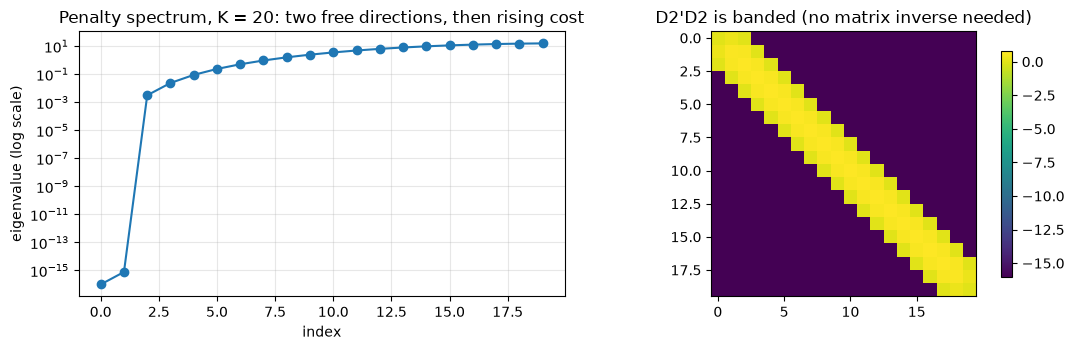

In [8]:
K_pen = 20
D2_diff = np.diff(np.eye(K_pen), n=2, axis=0)
P_diff = second_diff_penalty(K_pen, 1.0)
print("P == lam * D2'D2 :", bool(np.allclose(P_diff, D2_diff.T @ D2_diff)))
print("rank(P) =", np.linalg.matrix_rank(P_diff), " (theory: K - 2 =", K_pen - 2, ")")
print("P @ 1        =", float(np.abs(P_diff @ np.ones(K_pen)).max()))
print("P @ (0..K-1) =", float(np.abs(P_diff @ np.arange(K_pen)).max()))
print("P @ squares  =", float(np.abs(P_diff @ (np.arange(K_pen) ** 2.0)).max()))

Pc = circular_second_diff_penalty(12, 1.0)
print("\ncircular: rank =", np.linalg.matrix_rank(Pc), "of 12  (theory K - 1 = 11)")
print("circular: |Pc @ 1| =", float(np.abs(Pc @ np.ones(12)).max()))
print("circular: row 0 has entries at columns", np.flatnonzero(np.abs(Pc[0]) > 1e-12), "(the wrap)")

ridge = ridge_penalty(5, 2.0)
print("\nridge: P == 2 * I :", bool(np.allclose(ridge, 2.0 * np.eye(5))))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
evals = np.linalg.eigvalsh(P_diff)
axes[0].semilogy(np.maximum(evals, 1e-16), "o-")
axes[0].set(xlabel="index", ylabel="eigenvalue (log scale)",
            title=f"Penalty spectrum, K = {K_pen}: two free directions, then rising cost")
axes[0].grid(alpha=0.3, which="both")
im = axes[1].imshow(np.log10(np.abs(P_diff) + 1e-16), cmap="viridis")
axes[1].set(title="D2'D2 is banded (no matrix inverse needed)")
plt.colorbar(im, ax=axes[1], shrink=0.85)
plt.tight_layout()
plt.show()

assert np.allclose(P_diff, D2_diff.T @ D2_diff)
assert np.linalg.matrix_rank(P_diff) == K_pen - 2
assert np.abs(P_diff @ np.ones(K_pen)).max() < 1e-10
assert np.abs(P_diff @ np.arange(K_pen)).max() < 1e-10
assert np.abs(P_diff @ (np.arange(K_pen) ** 2.0)).max() > 1.0
assert np.linalg.matrix_rank(Pc) == 11
assert np.abs(Pc[0]).max() > 0 and np.flatnonzero(np.abs(Pc[0]) > 1e-12).size == 5
assert np.allclose(ridge, 2.0 * np.eye(5))

In [9]:
# --- the shape-constraint penalty C(beta) at work ---------------------------
beta_dip = np.array([0.0, 0.10, 0.22, 0.19, 0.30, 0.45])      # a dip at index 3
beta_mono = np.array([0.0, 0.10, 0.20, 0.30, 0.40, 0.50])     # increasing everywhere
beta_concave = np.array([0.0, 0.30, 0.10, 0.40])              # second differences go both ways

C_dip = shape_constraint_penalty(beta_dip, "mono_inc")
C_mono = shape_constraint_penalty(beta_mono, "mono_inc")
C_cvx = shape_constraint_penalty(beta_concave, "convex")

d1 = np.diff(beta_dip)
print("first differences of the dipping sequence:", np.round(d1, 3))
print("violating positions:", np.flatnonzero(d1 < 0), "  value:", np.round(d1[d1 < 0], 3))
print()
print(f"{'sequence':>16} {'constraint':>11} {'flag rows':>10} {'|C| max':>12}")
print(f"{'dipping':>16} {'mono_inc':>11} {np.count_nonzero(C_dip > 0):10d} {np.abs(C_dip).max():12.3g}")
print(f"{'increasing':>16} {'mono_inc':>11} {np.count_nonzero(C_mono > 0):10d} {np.abs(C_mono).max():12.3g}")
print(f"{'concave-ish':>16} {'convex':>11} {np.count_nonzero(C_cvx > 0):10d} {np.abs(C_cvx).max():12.3g}")
print("\nsecond differences of the concave-ish sequence:", np.round(np.diff(beta_concave, n=2), 3))

assert np.allclose(C_dip, C_dip.T) and np.linalg.eigvalsh(C_dip).min() > -1e-12
assert np.count_nonzero(C_dip) == 0 or np.abs(C_dip).max() > 1e6, "violations are charged hard"
assert np.abs(C_mono).max() == 0.0, "nothing to charge: the penalty switches itself off"
assert np.abs(C_cvx).max() > 1e6

first differences of the dipping sequence: [ 0.1   0.12 -0.03  0.11  0.15]
violating positions: [2]   value: [-0.03]

        sequence  constraint  flag rows      |C| max
         dipping    mono_inc          6        1e+09
      increasing    mono_inc          0            0
     concave-ish      convex          6        4e+09

second differences of the concave-ish sequence: [-0.5  0.5]


That last line is the whole trick. The penalty is built from the *current*
coefficients, so at a fit that already satisfies the constraint the violation set
is empty and the extra penalty vanishes: the constrained fit is a genuine least
squares fit subject to the shape, not a permanently distorted one.

---
# Part IV. The solver: a singular system, and the ridge that fixes it

The textbook route is the normal equation

$$(X^\top X + P)\,\hat{\boldsymbol\beta} = X^\top \mathbf{y}.$$

In this backend it is **singular**, and not by accident. Because the B-spline
basis satisfies the partition of unity, the vector of ones is in the column space
of $X$: the intercept column is redundant. And because the constant coefficient
sequence lies in the null space of $D_2$, the penalty does not charge that
combination either. Hence

$$\operatorname{rank}(X) = m - 1, \qquad
(X^\top X + P)\,v = 0
\quad\text{for}\quad
v = (\mathbf{1}, -1),$$

with $m$ the number of coefficients. Two things follow:

1. an *identifiability convention* is needed — here it is supplied implicitly by
   the tiny ridge below, so the reported decomposition keeps the level in the
   intercept and lets each smooth carry bending;
2. the solver cannot form $X^\top X$ and hope for the best.

**Data augmentation.** Write the penalty as fake data:
$E^\top E = P + \sqrt{\varepsilon} I$, and solve

$$\min_{\beta}\ \left\| \begin{pmatrix} X \\ E \end{pmatrix}\beta
- \begin{pmatrix} \mathbf{y} \\ 0 \end{pmatrix} \right\|^2,
\qquad \varepsilon = \text{machine epsilon}.$$

The extra $\sqrt{\varepsilon}$ on the diagonal is what makes the singular
direction invertible, and it is small enough ($\sim 10^{-8}$) to leave the
statistics essentially untouched. `magli` then factorises

$$X = QR, \qquad \begin{pmatrix} R \\ E \end{pmatrix} = U\Sigma V^\top,
\qquad B_{\text{solve}} = V\Sigma^{-1} U_1^\top Q^\top,$$

so that $\hat{\boldsymbol\beta} = B_{\text{solve}}\mathbf{y}$. The operator
$B_{\text{solve}}$ is reused for standard errors and intervals, and the effective
degrees of freedom come out of the same SVD with no matrix inverse:

$$\mathrm{EDF} = \|U_1\|_F^2
= \sum_i \sigma_i(U_1)^2
= \operatorname{tr}\!\big((X^\top X + P + \sqrt{\varepsilon}I)^{-1} X^\top X\big).$$

In [10]:
# --- build the system by hand and audit it ----------------------------------
m_num = LinGAM(n_splines=12, lam=1.0, backend="eilers").fit(x, y)
X = np.asarray(m_num.design_matrix_, dtype=float)
P = m_num._build_penalty()
m_coef = X.shape[1]
eps = np.finfo(float).eps
ridge_mat = np.sqrt(eps) * np.eye(m_coef)

print(f"X: {X.shape},  P: {P.shape},  intercept column is last")
print("rank(X) =", np.linalg.matrix_rank(X), " of m =", m_coef, "  <- the basis reproduces the constant")
evals_sing = np.linalg.eigvalsh(X.T @ X + P)
print("smallest eigenvalue of X'X + P      :", f"{evals_sing[0]:.3e}   (singular, as derived)")
print("smallest eigenvalue with the ridge  :", f"{np.linalg.eigvalsh(X.T @ X + P + ridge_mat)[0]:.3e}",
      f" ( = sqrt(eps) = {np.sqrt(eps):.3e} )")
print("condition numbers:  cond(X'X + P + ridge) =", f"{np.linalg.cond(X.T @ X + P + ridge_mat):.2e}")

E = np.linalg.cholesky(P + ridge_mat).T
print("                     cond([X; E])          =", f"{np.linalg.cond(np.vstack([X, E])):.2e}",
      " <- the augmented problem is far better conditioned")

# the solver...
Q, R = np.linalg.qr(X)
U, d, Vt = np.linalg.svd(np.vstack([R, E]), full_matrices=False)
U1 = U[:min(m_coef, X.shape[0]), :]
B_solve = (Vt.T / d) @ U1.T @ Q.T
beta_svd = B_solve @ y

# ... versus the ridge-regularised normal equations
beta_ne = np.linalg.solve(X.T @ X + P + ridge_mat, X.T @ y)
edf_svd = float(np.sum(U1**2))
edf_trace = float(np.trace(np.linalg.solve(X.T @ X + P + ridge_mat, X.T @ X)))

print("\nmax |beta_svd - beta_normal_eqns| =", f"{np.abs(beta_svd - beta_ne).max():.2e}")
print("max |beta_svd - beta_library|     =", f"{np.abs(beta_svd - m_num.coef_).max():.2e}")
print(f"EDF: ||U1||_F^2 = {edf_svd:.9f}   trace with ridge = {edf_trace:.9f}   statistics_ = {m_num.statistics_['edof']:.9f}")

assert np.linalg.matrix_rank(X) == m_coef - 1
assert abs(evals_sing[0]) < 1e-10, "without the ridge the system is singular"
assert abs(np.linalg.eigvalsh(X.T @ X + P + ridge_mat)[0] - np.sqrt(eps)) < 1e-12
assert np.abs(beta_svd - beta_ne).max() < 1e-5
assert np.abs(beta_svd - m_num.coef_).max() < 1e-12
assert abs(edf_svd - edf_trace) < 1e-6
assert abs(edf_svd - m_num.statistics_["edof"]) < 1e-12
assert np.linalg.cond(np.vstack([X, E])) < 1e6
assert np.linalg.cond(X.T @ X + P + ridge_mat) > 1e9

X: (200, 13),  P: (13, 13),  intercept column is last
rank(X) = 12  of m = 13   <- the basis reproduces the constant
smallest eigenvalue of X'X + P      : -6.938e-15   (singular, as derived)
smallest eigenvalue with the ridge  : 1.490e-08  ( = sqrt(eps) = 1.490e-08 )
condition numbers:  cond(X'X + P + ridge) = 1.48e+10
                     cond([X; E])          = 1.22e+05  <- the augmented problem is far better conditioned

max |beta_svd - beta_normal_eqns| = 2.03e-07
max |beta_svd - beta_library|     = 0.00e+00
EDF: ||U1||_F^2 = 6.613809859   trace with ridge = 6.613809779   statistics_ = 6.613809859


### Reading EDF coefficient by coefficient

`statistics_['edof_per_coef']` holds the diagonal of $U_1 U_1^\top$: how much of
each coefficient the fit actually uses. (The Wood backend reports the diagonal of
a *different* matrix, $F = (X^\top X + S_\lambda)^{-1}X^\top X$, in the
coefficient coordinates; the two definitions agree on the total, which is the
number the model comparison formulas need.)

Two practical readings:

* a sum close to $K$ means the penalty is doing very little;
* the last entry belongs to the intercept, and the redundant constant direction
  contributes ~0 — that is the rank deficiency showing up as a "wasted" degree of
  freedom, not as a warning.

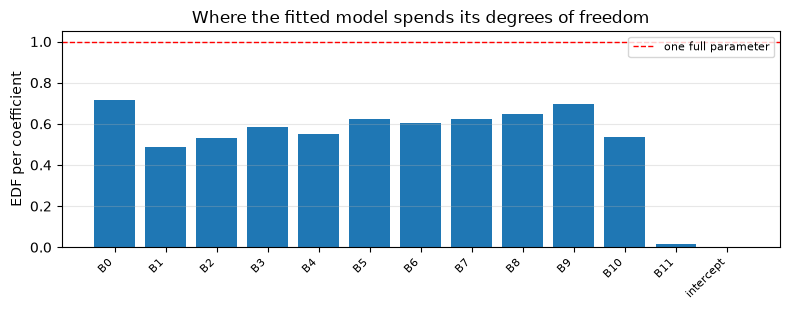

sum of per-coefficient EDF = 6.613809858858179   statistics_['edof'] = 6.613809858858179
largest single coefficient EDF: 0.7162510280286192
intercept entry: 3.941161551416861e-23


In [11]:
edof_per_coef = m_num.statistics_["edof_per_coef"]
labels = [f"B{j}" for j in range(edof_per_coef.size - 1)] + ["intercept"]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(edof_per_coef.size), edof_per_coef, color=["C0"] * (edof_per_coef.size - 1) + ["dimgray"])
ax.axhline(1.0, color="r", ls="--", lw=1, label="one full parameter")
ax.set_xticks(range(edof_per_coef.size))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set(ylabel="EDF per coefficient", title="Where the fitted model spends its degrees of freedom")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("sum of per-coefficient EDF =", float(edof_per_coef.sum()),
      "  statistics_['edof'] =", m_num.statistics_["edof"])
print("largest single coefficient EDF:", float(edof_per_coef.max()))
print("intercept entry:", float(edof_per_coef[-1]))

assert abs(float(edof_per_coef.sum()) - m_num.statistics_["edof"]) < 1e-12
assert edof_per_coef.max() <= 1.0 + 1e-12

---
# Part V. Choosing $(\lambda, K)$: GCV and an honest grid search

## 5.1 The criterion

$$\mathrm{GCV}(\lambda) = \frac{n \cdot \mathrm{RSS}}{(n - \gamma\,\mathrm{EDF})^2},
\qquad
\mathrm{RSS} = \sum_i (y_i - \hat y_i)^2,$$

with $\gamma = 1.4$ in this backend (the Wood backend uses $\gamma = 1$). The
denominator is the lever: a model that spends many effective parameters pays for
it, and the data have to buy that complexity with a lower RSS. The formula is a
closed-form approximation of leave-one-out cross-validation, which is why a whole
grid of candidate models costs milliseconds instead of a refit per point.

$\gamma > 1$ makes the criterion *slightly conservative* — it prefers simpler
models than $\gamma = 1$ would, and it is the reason the two backends can pick
different smoothing for the same data.

## 5.2 Why a grid, and why it is cheap

Instead of differentiating the criterion, `gridsearch()` evaluates a
user-visible lattice of candidates and keeps the winner. Two things make that
practical:

* **Phase 1, per $K$**: build $X_K$, compute $X_K = Q_K R_K$ once, cache
  $R_K^\top R_K$ and $R_K^\top Q_K^\top \mathbf{y}$ (both independent of
  $\lambda$), plus the unscaled penalty $S = D_2^\top D_2$.
* **Phase 2, per $(K,\lambda)$**: assemble $P = \lambda S$, Cholesky-solve
  $(R_K^\top R_K + P)\beta = R_K^\top Q_K^\top \mathbf{y}$, take EDF from the trace,
  record GCV.

The default $\lambda$ grid is `np.logspace(-3, 3, 11)` and, by default, *every*
penalised term shares the same candidate value at each evaluation (a diagonal
search). $K$ is not searched unless you pass `n_splines` grids. The cells below
measure both the win and the limits of that design.

hand GCV at the chosen lambda = 0.0251095376  statistics_['GCV'] = 0.0251095376


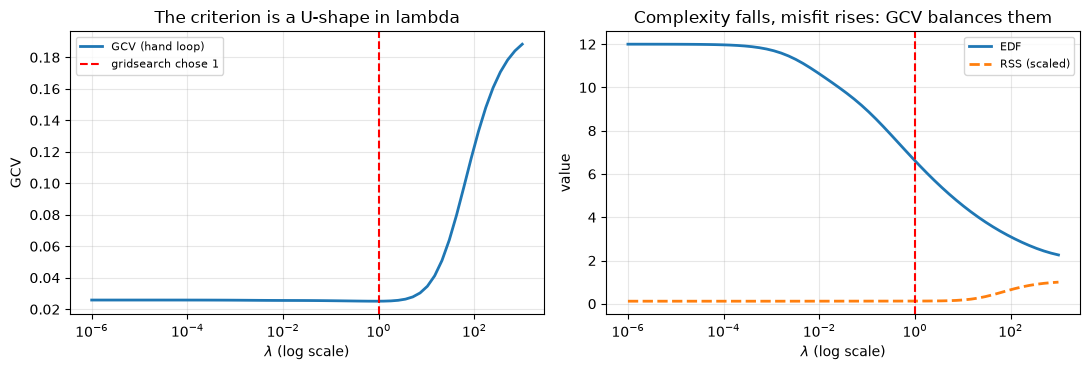


chosen lambda = 1   (the 11-point default grid)
fine-grid argmin = 0.8895   (a 60-point grid; the GCV curve is flat, so they agree)
EDF at the chosen lambda = 6.614;  EDF at lambda = 1e-6: 12.000;  at lambda = 1e3: 2.257


In [12]:
# --- the criterion, checked against the library -----------------------------
def gcv_of(m):
    n_obs = m.statistics_["n_samples"]
    return (n_obs * m.statistics_["rss"]) / (n_obs - 1.4 * m.statistics_["edof"]) ** 2


m_curves = LinGAM(n_splines=12, backend="eilers").gridsearch(x, y)
print("hand GCV at the chosen lambda =", round(gcv_of(m_curves), 10),
      " statistics_['GCV'] =", round(m_curves.statistics_["GCV"], 10))

lam_grid = np.logspace(-6, 3, 60)
edf_curve, gcv_curve, rss_curve = [], [], []
for lam in lam_grid:
    m_i = LinGAM(n_splines=12, lam=float(lam), backend="eilers").fit(x, y)
    edf_curve.append(m_i.statistics_["edof"])
    gcv_curve.append(m_i.statistics_["GCV"])
    rss_curve.append(m_i.statistics_["rss"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogx(lam_grid, gcv_curve, lw=2, label="GCV (hand loop)")
axes[0].axvline(m_curves.lam, color="r", ls="--", label=f"gridsearch chose {m_curves.lam:g}")
axes[0].set(xlabel=r"$\lambda$ (log scale)", ylabel="GCV", title="The criterion is a U-shape in lambda")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3, which="both")
axes[1].semilogx(lam_grid, edf_curve, lw=2, label="EDF")
axes[1].semilogx(lam_grid, np.array(rss_curve) / max(rss_curve), lw=2, ls="--", label="RSS (scaled)")
axes[1].axvline(m_curves.lam, color="r", ls="--")
axes[1].set(xlabel=r"$\lambda$ (log scale)", ylabel="value",
            title="Complexity falls, misfit rises: GCV balances them")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

argmin_lam = float(lam_grid[int(np.argmin(gcv_curve))])
print(f"\nchosen lambda = {m_curves.lam:g}   (the 11-point default grid)")
print(f"fine-grid argmin = {argmin_lam:.4g}   (a 60-point grid; the GCV curve is flat, so they agree)")
print(f"EDF at the chosen lambda = {m_curves.statistics_['edof']:.3f};  "
      f"EDF at lambda = 1e-6: {edf_curve[0]:.3f};  at lambda = 1e3: {edf_curve[-1]:.3f}")

assert abs(gcv_of(m_curves) - m_curves.statistics_["GCV"]) < 1e-12
assert (m_curves.statistics_["GCV"] - min(gcv_curve)) / min(gcv_curve) < 0.01, \
    "the grid pick sits on the curve's minimum"
assert gcv_curve[0] > m_curves.statistics_["GCV"] and gcv_curve[-1] > m_curves.statistics_["GCV"]

In [13]:
# --- what gamma does --------------------------------------------------------
print(f"{'gamma':>6} {'chosen lambda':>14} {'EDF':>7} {'GCV':>10}")
gamma_rows = []
for gamma in (1.0, 1.2, 1.4, 1.8, 2.5):
    m_g = LinGAM(n_splines=12, backend="eilers").gridsearch(x, y, gamma=gamma)
    gamma_rows.append((gamma, m_g.lam, m_g.statistics_["edof"], m_g.statistics_["GCV"]))
    print(f"{gamma:6.1f} {m_g.lam:14.5g} {m_g.statistics_['edof']:7.3f} {m_g.statistics_['GCV']:10.6f}")

print("\nlarger gamma = a stricter complexity tax = more smoothing (when it bites at all)")
assert gamma_rows[0][1] <= gamma_rows[-1][1]

 gamma  chosen lambda     EDF        GCV
   1.0        0.25119   8.048   0.024422
   1.2              1   6.614   0.024765
   1.4              1   6.614   0.025110
   1.8              1   6.614   0.025821
   2.5              1   6.614   0.027140

larger gamma = a stricter complexity tax = more smoothing (when it bites at all)


In [14]:
# --- is the cached grid actually faster? ------------------------------------
Ks = np.arange(6, 15, 2)
lams = np.logspace(-3, 3, 11)

t0 = time.perf_counter()
best = LinGAM(n_splines=12, backend="eilers").gridsearch(x, y, lam=lams, n_splines=Ks)
t_grid = time.perf_counter() - t0

t0 = time.perf_counter()
surface = np.zeros((Ks.size, lams.size))
for i, K_i in enumerate(Ks):
    for j, lam_j in enumerate(lams):
        surface[i, j] = LinGAM(n_splines=int(K_i), lam=float(lam_j), backend="eilers").fit(x, y).statistics_["GCV"]
t_naive = time.perf_counter() - t0

i_best, j_best = np.unravel_index(np.argmin(surface), surface.shape)
print(f"gridsearch(): {t_grid*1000:6.1f} ms      naive refit loop: {t_naive*1000:6.1f} ms"
      f"      ratio: {t_naive/t_grid:.1f}x   ({Ks.size} x {lams.size} = {Ks.size*lams.size} candidates)")
print(f"naive argmin      : K = {Ks[i_best]}, lambda = {lams[j_best]:.5g}, GCV = {surface[i_best, j_best]:.9f}")
print(f"gridsearch() pick : K = {best.n_splines}, lambda = {best.lam:.5g}, GCV = {best.statistics_['GCV']:.9f}")

assert abs(surface[i_best, j_best] - best.statistics_["GCV"]) < 1e-9
assert int(Ks[i_best]) == best.n_splines and abs(float(lams[j_best]) - best.lam) < 1e-12
assert t_naive > t_grid

gridsearch():    4.9 ms      naive refit loop:   32.8 ms      ratio: 6.7x   (5 x 11 = 55 candidates)
naive argmin      : K = 6, lambda = 0.015849, GCV = 0.024683670
gridsearch() pick : K = 6, lambda = 0.015849, GCV = 0.024683670


### The grid-search API in one place

| goal | call |
|---|---|
| default search (11 lambdas, one shared value for all penalised terms) | `model.gridsearch(x, y)` |
| change the criterion's conservatism | `model.gridsearch(x, y, gamma=1.0)` |
| tune only some terms | `model.gridsearch(X, y, search_terms=['s'])` or `[0, 'f']` |
| search $K$ as well | `n_splines=np.arange(6, 15, 2)` (one grid per slot) |
| give each term its own candidates | `lam_grids=[g1, g2, ...]` (one array per slot; the Cartesian product is searched) |
| list explicit candidate *vectors* | `lam=np.array([[...], [...]])` — a 2-D array of rows, one column per slot |
| share the work across cores | `n_jobs=-1` (see the honest measurement below) |

`search_terms` defaults to *every penalised term*, i.e. everything except `l()`
linear terms, which stay unpenalised unless you search them explicitly.

In [15]:
# --- search_terms, per-term lambdas, and the n_jobs reality check -----------
X2 = np.column_stack([x, rng.uniform(0.0, 1.0, n)])
y2 = y + 0.6 * X2[:, 1]
m_default = GAMCore("s(0, n_splines=12) + l(1)", backend="eilers").gridsearch(X2, y2, lam=lams)
m_all = GAMCore("s(0, n_splines=12) + l(1)", backend="eilers").gridsearch(X2, y2, lam=lams, search_terms="all")
print("default search : spline lam =", round(m_default._terms[0].lam, 5), "  linear lam =", m_default._terms[1].lam)
print("search_terms='all': spline lam =", round(m_all._terms[0].lam, 5), "  linear lam =", round(m_all._terms[1].lam, 5))
assert m_default._terms[1].lam == 0.0, "l() terms are unpenalised unless searched"
assert m_all._terms[1].lam != 0.0

# shared lambda vs independent lambdas on a two-smooth model
X_th = np.column_stack([x, X2[:, 1]])
shared = GAMCore("s(0, n_splines=12) + s(1, n_splines=12)", backend="eilers")
shared.gridsearch(X_th, y2, lam=np.logspace(-3, 3, 11))
pair_grid = np.logspace(-3, 3, 9)
indep = GAMCore("s(0, n_splines=12) + s(1, n_splines=12)", backend="eilers")
indep.gridsearch(X_th, y2, lam_grids=[pair_grid, pair_grid])
print(f"\nshared lambda  : {shared._terms[0].lam:.4g}      GCV = {shared.statistics_['GCV']:.6f}"
      f"   EDF = {shared.statistics_['edof']:.2f}")
print(f"independent    : {np.round([t.lam for t in indep._terms], 4)}  GCV = {indep.statistics_['GCV']:.6f}"
      f"   EDF = {indep.statistics_['edof']:.2f}")
assert indep.statistics_["GCV"] < shared.statistics_["GCV"]
assert indep._terms[0].lam != indep._terms[1].lam

# n_jobs: same answer, and no free lunch at this size
rng_nj = np.random.default_rng(21)
X_nj = rng_nj.uniform(0.0, 1.0, (400, 2))
y_nj = np.sin(2 * np.pi * X_nj[:, 0]) + np.cos(2 * np.pi * X_nj[:, 1]) + rng_nj.normal(0, 0.2, 400)
timings, answers = {}, {}
for jobs in (1, -1):
    m_nj = GAMCore("s(0, n_splines=15) + s(1, n_splines=15)", backend="eilers")
    t0 = time.perf_counter()
    m_nj.gridsearch(X_nj, y_nj, lam_grids=[np.logspace(-2, 2, 5)] * 2,
                    n_splines_grids=[np.array([10, 14, 18])] * 2, n_jobs=jobs)
    timings[jobs] = time.perf_counter() - t0
    answers[jobs] = (round(m_nj.statistics_["GCV"], 10), [t.n_splines for t in m_nj._terms],
                     round(float(m_nj._terms[0].lam), 10))
print(f"\nn_jobs=1 : {timings[1]*1000:6.1f} ms     n_jobs=-1: {timings[-1]*1000:6.1f} ms")
print("identical results:", answers[1] == answers[-1])
print("(at this problem size the threading overhead cancels the gain; leave n_jobs=1)")
assert answers[1] == answers[-1]

default search : spline lam = 1.0   linear lam = 0.0
search_terms='all': spline lam = 1.0   linear lam = 1.0

shared lambda  : 1      GCV = 0.026625   EDF = 12.20
independent    : [   1. 1000.]  GCV = 0.025525   EDF = 7.86

n_jobs=1 :   38.7 ms     n_jobs=-1:   47.4 ms
identical results: True
(at this problem size the threading overhead cancels the gain; leave n_jobs=1)


---
# Part VI. Inference: one covariance, no p-values

There is exactly one covariance matrix here — the **frequentist** one, obtained
by propagating the sampling variability of $\hat{\boldsymbol\beta}$ through the
saved solve operator:

$$\operatorname{Cov}(\hat{\boldsymbol\beta}) = B_{\text{solve}}B_{\text{solve}}^\top \hat\sigma^2,
\qquad
\hat\sigma = \sqrt{\frac{\mathrm{RSS}}{n - \mathrm{EDF}}},$$

and predictions carry

$$\operatorname{Var}\big(\hat y(\mathbf{x}^*)\big)
= \mathbf{x}^{*\top}\operatorname{Cov}(\hat{\boldsymbol\beta})\,\mathbf{x}^*,$$

with $t$-quantiles on $n - \mathrm{EDF}$ degrees of freedom; prediction intervals
add $\hat\sigma^2$.

Three consequences to keep straight, especially when switching notebooks:

* **No `summary()`.** There is no formatted table, no approximate F-tests and no
  p-values: the Wood backend's whole inference kit is absent by design. Model
  comparison goes through GCV, AIC/BIC and deviance explained instead.
* **`scale` is $\hat\sigma$, not $\hat\sigma^2$.** The Wood backend stores the
  variance; this one stores the standard deviation. Interval code must add
  `scale**2`, and `wood.statistics_['scale']` is *not* the same kind of number.
* **The covariance treats $\lambda$ as known**, exactly like the Wood backend's
  $V_e$; intervals are slightly optimistic because the tuning step is ignored.

SEs stored in statistics_ equal sqrt(diag(cov)): True
max |CI hand - library| = 0.0
max |PI hand - library| = 0.0

scale is sigma: 0.1537  -> variance = scale**2 = 0.0236
band widths at the first point: confidence 0.1314  prediction 0.6203


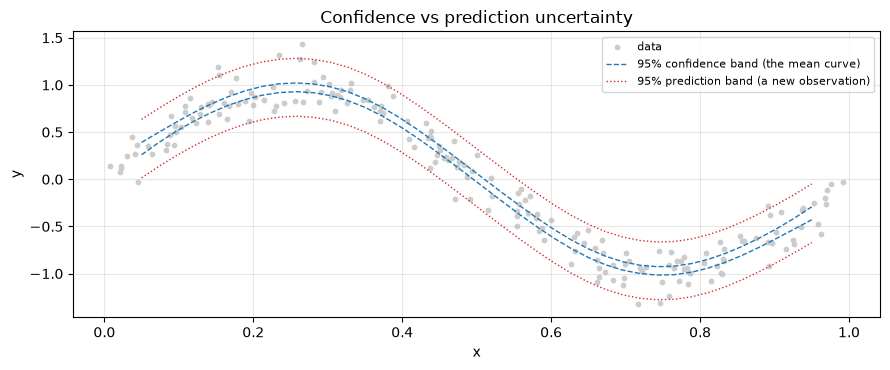

In [16]:
# --- rebuild the standard errors and both intervals by hand -----------------
x_eval = np.linspace(0.05, 0.95, 40)
mu = m_curves.predict(x_eval)
B_eval = b_spline_basis(x_eval, 12, 3, np.array([x.min(), x.max()]))
X_eval = np.column_stack([B_eval, np.ones(x_eval.size)])     # basis columns + intercept
cov = m_curves.statistics_["cov"]

se_hand = np.sqrt(np.sum((X_eval @ cov) * X_eval, axis=1))
df_resid = max(m_curves.statistics_["n_samples"] - m_curves.statistics_["edof"], 1.0)
t_q = stats.t.ppf(0.975, df_resid)
ci = m_curves.confidence_intervals(x_eval, width=0.95)
pi = m_curves.prediction_intervals(x_eval, width=0.95)
ci_hand = np.column_stack([mu - t_q * se_hand, mu + t_q * se_hand])
pi_hand = np.column_stack([mu - t_q * np.sqrt(se_hand**2 + m_curves.statistics_["scale"] ** 2),
                           mu + t_q * np.sqrt(se_hand**2 + m_curves.statistics_["scale"] ** 2)])

print("SEs stored in statistics_ equal sqrt(diag(cov)):",
      bool(np.allclose(m_curves.statistics_["se"], np.sqrt(np.diag(cov)))))
print("max |CI hand - library| =", float(np.abs(ci_hand - ci).max()))
print("max |PI hand - library| =", float(np.abs(pi_hand - pi).max()))
print("\nscale is sigma:", round(m_curves.statistics_["scale"], 4),
      " -> variance = scale**2 =", round(m_curves.statistics_["scale"] ** 2, 4))
print("band widths at the first point: confidence", round(float(ci[0, 1] - ci[0, 0]), 4),
      " prediction", round(float(pi[0, 1] - pi[0, 0]), 4))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(x, y, s=10, color="0.8", label="data")
ax.plot(x_eval, ci[:, 0], "C0--", lw=1)
ax.plot(x_eval, ci[:, 1], "C0--", lw=1, label="95% confidence band (the mean curve)")
ax.plot(x_eval, pi[:, 0], "C3:", lw=1)
ax.plot(x_eval, pi[:, 1], "C3:", lw=1, label="95% prediction band (a new observation)")
ax.set(xlabel="x", ylabel="y", title="Confidence vs prediction uncertainty")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert np.abs(ci_hand - ci).max() < 1e-9
assert np.abs(pi_hand - pi).max() < 1e-9
assert np.all(pi[:, 1] - pi[:, 0] > ci[:, 1] - ci[:, 0])
assert not hasattr(m_curves, "summary"), "there is no summary table in this backend"
assert EilersLinGAM._scale_is_var is False and WoodLinGAM._scale_is_var is True

---
# Part VII. The workflow

The recipe for this backend is shorter than for the Wood one, because there is no
estimator to trust — you choose the search space yourself:

1. **Look at the data**: ranges, units, outliers, cyclic covariates, and whether
   any effect must be monotone or convex (that is what this backend is for).
2. **Write a formula**: `s(j, n_splines=...)` per continuous covariate, `l(j)` for
   effects you believe are linear, `f(j)` for factors.
3. **`gridsearch()`** with the default grid first, then refine.
4. **Read the numbers**: per-term EDF (sum `edof_per_coef` over the coefficient
   slices), GCV, AIC/BIC, deviance explained, $\hat\sigma$.
5. **Compare candidate formulas** on the same data — this is where model selection
   happens in a GCV world.
6. **Add the constraints you believe in** (`mono_inc` and friends) and check what
   they cost.
7. **Report**: `predict`, both interval types, `partial_dependence`,
   `plot_decomposition`, `plot_diagnostics`.

We use the same simulated tool-life dataset as the Wood notebook, so the two
notebooks' numbers can be put side by side.

| variable | meaning | role in the simulation |
|---|---|---|
| `temp` | cutting temperature (°C) | quadratic optimum around 250 °C |
| `speed` | spindle speed (m/min) | sinusoidal, levelling off |
| `humid` | ambient humidity (%) | **interacts** with temperature |
| `shift` | shift identity (0, 1, 2) | small additive level effect |

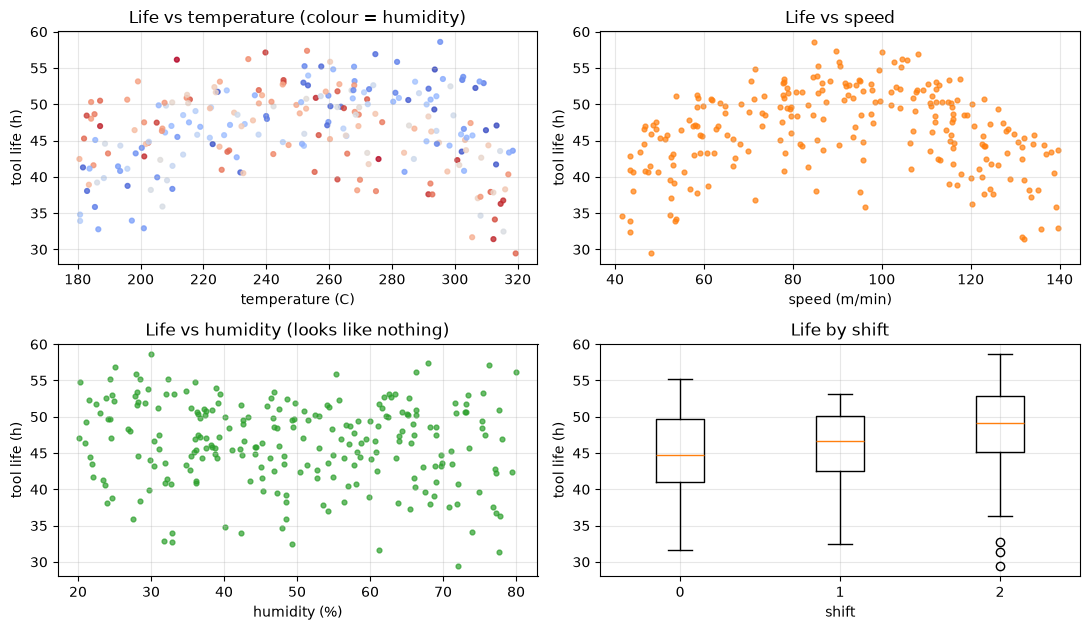

range: [180.5  41.5  20.2   0. ] to [319.4 139.7  79.9   2. ]
expected noise sd: 1.6


In [17]:
rng_wf = np.random.default_rng(7)
n_wf = 240
temp = rng_wf.uniform(180.0, 320.0, n_wf)
speed = rng_wf.uniform(40.0, 140.0, n_wf)
humid = rng_wf.uniform(20.0, 80.0, n_wf)
shift = rng_wf.choice([0.0, 1.0, 2.0], n_wf)
life = (40.0
        - 0.002 * (temp - 250.0) ** 2
        + 12.0 * np.sin((speed - 40.0) / 100.0 * np.pi)
        + 6.0 * np.cos(2 * np.pi * temp / 200.0) * (humid - 50.0) / 30.0
        + 1.5 * shift
        + rng_wf.normal(0.0, 1.6, n_wf))
X_wf = np.column_stack([temp, speed, humid, shift])
feature_names = ["temp", "speed", "humid", "shift"]
lam_default = np.logspace(-3, 3, 11)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
axes[0, 0].scatter(temp, life, s=12, c=humid, cmap="coolwarm", alpha=0.8)
axes[0, 0].set(xlabel="temperature (C)", ylabel="tool life (h)", title="Life vs temperature (colour = humidity)")
axes[0, 1].scatter(speed, life, s=12, color="C1", alpha=0.7)
axes[0, 1].set(xlabel="speed (m/min)", ylabel="tool life (h)", title="Life vs speed")
axes[1, 0].scatter(humid, life, s=12, color="C2", alpha=0.7)
axes[1, 0].set(xlabel="humidity (%)", ylabel="tool life (h)", title="Life vs humidity (looks like nothing)")
axes[1, 1].boxplot([life[shift == s] for s in (0.0, 1.0, 2.0)], tick_labels=["0", "1", "2"])
axes[1, 1].set(xlabel="shift", ylabel="tool life (h)", title="Life by shift")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("range:", np.round(X_wf.min(axis=0), 1), "to", np.round(X_wf.max(axis=0), 1))
print("expected noise sd: 1.6")

In [18]:
# --- a tiny reporting helper: per-term EDF from edof_per_coef ---------------
def term_edf(model):
    # statistics_ has no per-term breakdown; the coefficient slices provide it
    return np.round([float(model.statistics_["edof_per_coef"][s:e].sum())
                     for s, e in model._coef_slices], 3)


def report(model, label):
    print(f"{label:>22} | lam {np.round([float(t.lam) for t in model._terms], 4)}")
    print(f"{'':>22} | EDF(term) {term_edf(model)}  total {model.statistics_['edof']:.2f}")
    print(f"{'':>22} | GCV {model.statistics_['GCV']:8.4f}   AIC {model.aic():9.2f}   BIC {model.bic():9.2f}")
    print(f"{'':>22} | deviance explained {model.deviance_explained():.4f}   sigma {model.statistics_['scale']:.4f}")


formula_add = "s(0, n_splines=12) + s(1, n_splines=10) + s(2, n_splines=10) + f(3)"
m_add = GAMCore(formula_add, backend="eilers").gridsearch(X_wf, life, lam=lam_default)
report(m_add, "additive")

assert m_add.statistics_["scale"] > 2.5, "sigma is inflated: the additive formula is missing the interaction"
assert term_edf(m_add).size == 4

              additive | lam [3.9811 3.9811 3.9811 3.9811]
                       | EDF(term) [5.674 3.685 3.481 1.764]  total 14.60
                       | GCV  11.0112   AIC   1245.76   BIC   1300.08
                       | deviance explained 0.7201   sigma 3.1324


In [19]:
# --- compare candidate formulas on the same data ---------------------------
candidates = {
    "additive": formula_add,
    "additive minus humid": "s(0, n_splines=12) + s(1, n_splines=10) + f(3)",
    "te(temp, humid)": "te(0, 2, n_splines=6) + s(1, n_splines=10) + f(3)",
    "te + marginals": "s(0, n_splines=12) + s(2, n_splines=10) + te(0, 2, n_splines=5) + s(1, n_splines=10) + f(3)",
}
wf_fits = {}
print(f"{'model':>22} {'EDF':>7} {'GCV':>9} {'AIC':>9} {'BIC':>9} {'dev.exp':>8} {'sigma':>7}")
for label, form in candidates.items():
    m_c = GAMCore(form, backend="eilers").gridsearch(X_wf, life, lam=lam_default)
    wf_fits[label] = m_c
    print(f"{label:>22} {m_c.statistics_['edof']:7.2f} {m_c.statistics_['GCV']:9.4f} "
          f"{m_c.aic():9.2f} {m_c.bic():9.2f} {m_c.deviance_explained():8.4f} {m_c.statistics_['scale']:7.4f}")
    print(f"{'':>22}   per-term EDF {term_edf(m_c)}")

best_te = wf_fits["te(temp, humid)"]
print("\nthe marginal temperature and humidity terms of the additive model:")
print("   additive   :", term_edf(wf_fits["additive"]))
print("   minus humid:", term_edf(wf_fits["additive minus humid"]))

assert best_te.statistics_["GCV"] < 0.5 * wf_fits["additive"].statistics_["GCV"]
assert abs(best_te.statistics_["scale"] - 1.6) < 0.4, "with the interaction the residual sd matches the simulation"
assert wf_fits["te + marginals"].statistics_["GCV"] > best_te.statistics_["GCV"]

                 model     EDF       GCV       AIC       BIC  dev.exp   sigma
              additive   14.60   11.0112   1245.76   1300.08   0.7201  3.1324
                         per-term EDF [5.674 3.685 3.481 1.764]
  additive minus humid   11.01   10.9145   1247.13   1288.93   0.7097  3.1650
                         per-term EDF [5.602 3.599 1.806]
       te(temp, humid)   24.99    2.7930    905.35    995.82   0.9381  1.5083
                         per-term EDF [16.271  6.919  1.802]
        te + marginals   38.68    3.1700    918.10   1056.23   0.9423  1.5053
                         per-term EDF [11.817  8.875  8.126  8.03   1.835]

the marginal temperature and humidity terms of the additive model:
   additive   : [5.674 3.685 3.481 1.764]
   minus humid: [5.602 3.599 1.806]


Read that table the way a GCV practitioner reads it:

* The additive model's $\hat\sigma \approx 3.1$ against a simulated noise of $1.6$
  — it is fitting structure it cannot represent, so the residual variance absorbs it.
* Adding `te(temp, humid)` cuts GCV from ~11 to ~2.8 and $\hat\sigma$ to ~1.5.
  That is the interaction.
* The two criteria **disagree by a hair** about the weak `s(humid)` term in the
  additive model (GCV prefers dropping it, AIC prefers keeping it). When two
  criteria disagree by a percent on a term whose EDF is a couple of parameters,
  the honest conclusion is "this term does almost nothing" — not "criterion X is
  right".
* In the Wood backend, shrinkage bases let REML switch a redundant term off
  (EDF $\to 0$). Here a second-difference penalty can only *straighten* a term
  (EDF $\to 1$), so redundant terms cost both GCV and AIC. **Do not add terms you
  do not want.** Model selection in this backend means writing candidate
  formulas and comparing them, as above.

         model    lambda     min step     EDF      MAE
 unconstrained    3.1623    -4.85e-04    5.77   0.0932
      mono_inc    3.1623    -7.12e-12    4.68   0.0896
convex (wrong)       0.1     7.12e-03    2.00   0.3897


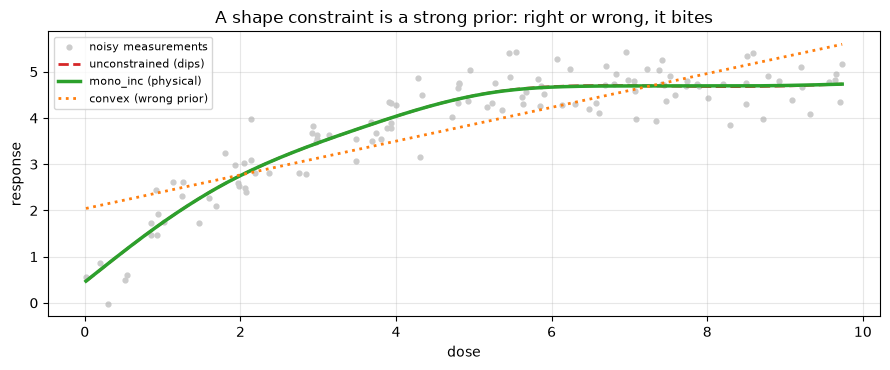

In [20]:
# --- shape constraints on a dose-response curve -----------------------------
rng_dose = np.random.default_rng(3)
dose = np.sort(rng_dose.uniform(0.0, 10.0, 120))
dose_truth = 5.0 * (1.0 - np.exp(-0.4 * dose))          # increasing and concave: saturating
response = dose_truth + rng_dose.normal(0.0, 0.45, dose.size)
lam_dose = np.logspace(-4, 3, 15)

unconstrained = LinGAM(n_splines=14, backend="eilers").gridsearch(dose, response, lam=lam_dose)
mono = LinGAM(n_splines=14, constraint="mono_inc", backend="eilers").gridsearch(dose, response, lam=lam_dose)
wrong_convex = LinGAM(n_splines=14, constraint="convex", backend="eilers").gridsearch(dose, response, lam=lam_dose)

dose_grid = np.linspace(dose.min(), dose.max(), 500)
min_delta = lambda m: float(np.diff(m.predict(dose_grid)).min())
mae = lambda m: float(np.mean(np.abs(m.predict(dose) - dose_truth)))

print(f"{'model':>14} {'lambda':>9} {'min step':>12} {'EDF':>7} {'MAE':>8}")
for label, m_c in (("unconstrained", unconstrained), ("mono_inc", mono), ("convex (wrong)", wrong_convex)):
    print(f"{label:>14} {m_c.lam:9.5g} {min_delta(m_c):12.2e} {m_c.statistics_['edof']:7.2f} {mae(m_c):8.4f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(dose, response, s=12, color="0.8", label="noisy measurements")
ax.plot(dose_grid, unconstrained.predict(dose_grid), "C3--", lw=2, label="unconstrained (dips)")
ax.plot(dose_grid, mono.predict(dose_grid), "C2-", lw=2.5, label="mono_inc (physical)")
ax.plot(dose_grid, wrong_convex.predict(dose_grid), "C1:", lw=2, label="convex (wrong prior)")
ax.set(xlabel="dose", ylabel="response", title="A shape constraint is a strong prior: right or wrong, it bites")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert min_delta(unconstrained) < -1e-6, "the unconstrained fit really does dip"
assert min_delta(mono) > -1e-9, "mono_inc removes every decreasing step"
assert mae(mono) < mae(unconstrained), "and it helps for this truth"
assert mae(wrong_convex) > 2 * mae(unconstrained), "the wrongly imposed prior is much worse"

unconstrained: min 2nd difference = -1.744e-02   EDF =  29.01   MAE = 0.1545
convex       : min 2nd difference = -3.252e-12   EDF =  11.99   MAE = 0.0704


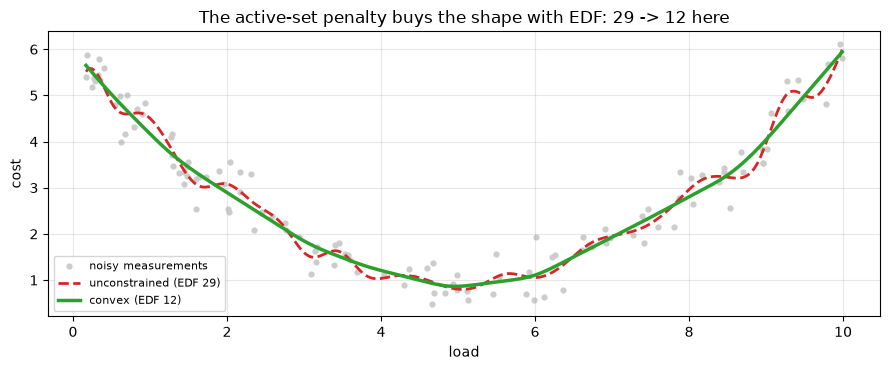

In [21]:
# --- same basis, same lambda, constraint on/off -----------------------------
rng_cost = np.random.default_rng(11)
cost_x = np.sort(rng_cost.uniform(0.0, 10.0, 120))
cost_truth = (cost_x - 5.0) ** 2 / 5.0 + 1.0             # U-shaped: convex by construction
cost_y = cost_truth + rng_cost.normal(0.0, 0.4, cost_x.size)

K_cost, lam_cost = 30, 1e-3
plain_cost = LinGAM(n_splines=K_cost, lam=lam_cost, backend="eilers").fit(cost_x, cost_y)
convex_cost = LinGAM(n_splines=K_cost, lam=lam_cost, constraint="convex", backend="eilers").fit(cost_x, cost_y)
cost_grid = np.linspace(cost_x.min(), cost_x.max(), 500)
d2_of = lambda m: float(np.diff(m.predict(cost_grid), 2).min())
mae_of = lambda m: float(np.mean(np.abs(m.predict(cost_x) - cost_truth)))
print(f"unconstrained: min 2nd difference = {d2_of(plain_cost): .3e}   EDF = {plain_cost.statistics_['edof']:6.2f}   MAE = {mae_of(plain_cost):.4f}")
print(f"convex       : min 2nd difference = {d2_of(convex_cost): .3e}   EDF = {convex_cost.statistics_['edof']:6.2f}   MAE = {mae_of(convex_cost):.4f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(cost_x, cost_y, s=12, color="0.8", label="noisy measurements")
ax.plot(cost_grid, plain_cost.predict(cost_grid), "C3--", lw=2, label=f"unconstrained (EDF {plain_cost.statistics_['edof']:.0f})")
ax.plot(cost_grid, convex_cost.predict(cost_grid), "C2-", lw=2.5, label=f"convex (EDF {convex_cost.statistics_['edof']:.0f})")
ax.set(xlabel="load", ylabel="cost", title="The active-set penalty buys the shape with EDF: 29 -> 12 here")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert d2_of(plain_cost) < -1e-3, "at this lambda the unconstrained fit is visibly non-convex"
assert d2_of(convex_cost) > -1e-9
assert mae_of(convex_cost) < 0.6 * mae_of(plain_cost)
assert convex_cost.statistics_["edof"] < plain_cost.statistics_["edof"]

training ranges: exact [0, 24] vs random [0.058, 23.915]
K_eff = 11 of K = 14 (the last k columns are folded in)
f(0) vs f(24): exact-range gap = 0.00e+00   loose-range gap = 2.98e-01
f(6) vs f(30): exact-range gap = 0.00e+00
wrapped fit at 6h: 22.956 vs the raw data mean at 6h: 23.314


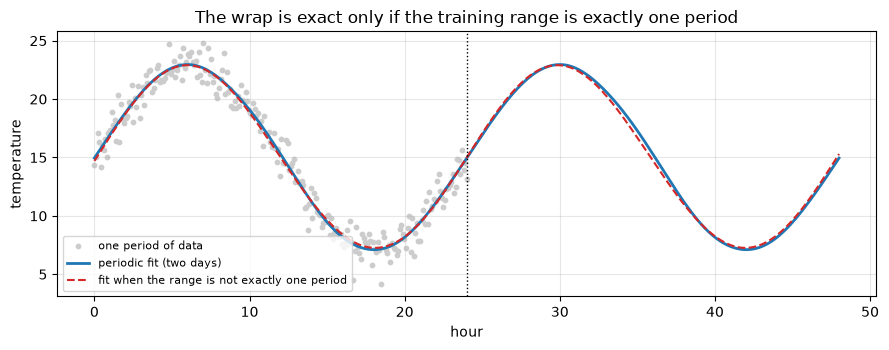

In [22]:
# --- periodic smooths: the wrap follows the training range ------------------
rng_per = np.random.default_rng(4)
hour_exact = np.linspace(0.0, 24.0, 240)                  # exactly one period
temp_exact = 15.0 + 8.0 * np.sin(2 * np.pi * hour_exact / 24.0) + rng_per.normal(0.0, 1.0, 240)
m_exact = LinGAM(n_splines=14, constraint="periodic", backend="eilers").gridsearch(hour_exact, temp_exact)

hour_loose = rng_per.uniform(0.0, 24.0, 240)              # the range is ~23.9, not 24
temp_loose = 15.0 + 8.0 * np.sin(2 * np.pi * hour_loose / 24.0) + rng_per.normal(0.0, 1.0, 240)
m_loose = LinGAM(n_splines=14, constraint="periodic", backend="eilers").gridsearch(hour_loose, temp_loose)

gap = lambda m: abs(float(m.predict([0.0])[0]) - float(m.predict([24.0])[0]))
print("training ranges: exact [0, 24] vs random [%.3f, %.3f]" % (hour_loose.min(), hour_loose.max()))
print("K_eff =", m_exact.n_coefs, "of K =", m_exact.n_splines, "(the last k columns are folded in)")
print(f"f(0) vs f(24): exact-range gap = {gap(m_exact):.2e}   loose-range gap = {gap(m_loose):.2e}")
print(f"f(6) vs f(30): exact-range gap = {abs(float(m_exact.predict([6.0])[0]) - float(m_exact.predict([30.0])[0])):.2e}")
print(f"wrapped fit at 6h: {float(m_exact.predict([6.0])[0]):.3f} vs the raw data mean at 6h: "
      f"{float(temp_exact[(hour_exact > 5.5) & (hour_exact < 6.5)].mean()):.3f}")

two_days = np.linspace(0.0, 48.0, 600)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(hour_exact, temp_exact, s=10, color="0.8", label="one period of data")
ax.plot(two_days, m_exact.predict(two_days.reshape(-1, 1)), "C0-", lw=2, label="periodic fit (two days)")
ax.plot(two_days, m_loose.predict(two_days.reshape(-1, 1)), "C3--", lw=1.5,
        label="fit when the range is not exactly one period")
ax.axvline(24.0, color="k", ls=":", lw=1)
ax.set(xlabel="hour", ylabel="temperature", title="The wrap is exact only if the training range is exactly one period")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert gap(m_exact) < 1e-9 and abs(float(m_exact.predict([6.0])[0]) - float(m_exact.predict([30.0])[0])) < 1e-9
assert gap(m_loose) > 0.05, "a loose training range leaves a step at the seam"
assert m_exact.n_coefs == m_exact.n_splines - 3

candidate vectors (rows) gave lam_per = [0.01 1.  ]  GCV = 2.724
broadcast search earlier gave lam_per = [0.0158 0.0158]  GCV = 2.79304
te term: EDF = 11.329 of 36 coefficients


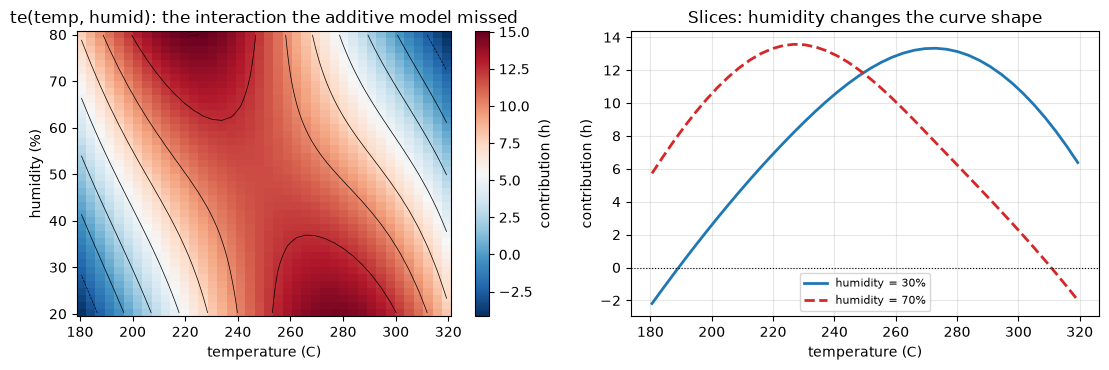

In [23]:
# --- the interaction term, with one lambda per dimension --------------------
lam_rows = np.array([[l1, l2, 1.0, 1.0]
                     for l1 in (0.01, 0.1, 1.0)
                     for l2 in (0.01, 0.1, 1.0)])
m_te = GAMCore("te(0, 2, n_splines=6) + s(1, n_splines=10) + f(3)", backend="eilers")
m_te.gridsearch(X_wf, life, lam=lam_rows)
te_slice = m_te._coef_slices[0]
te_edf = float(m_te.statistics_["edof_per_coef"][te_slice[0]:te_slice[1]].sum())
print("candidate vectors (rows) gave lam_per =", np.round(m_te._terms[0].lam_per, 4),
      " GCV =", round(m_te.statistics_["GCV"], 5))
print("broadcast search earlier gave lam_per =", np.round(best_te._terms[0].lam_per, 4),
      " GCV =", round(best_te.statistics_["GCV"], 5))
print("te term: EDF =", round(te_edf, 3), "of", m_te._terms[0].n_coefs, "coefficients")

grid_t = np.linspace(temp.min(), temp.max(), 40)
grid_h = np.linspace(humid.min(), humid.max(), 40)
GT, GH = np.meshgrid(grid_t, grid_h, indexing="ij")
pts = np.column_stack([GT.ravel(), np.full(GT.size, speed.mean()), GH.ravel(), np.zeros(GT.size)])
surface = m_te.partial_dependence(0, pts).reshape(GT.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
im = axes[0].pcolormesh(GT, GH, surface, cmap="RdBu_r", shading="auto")
axes[0].contour(GT, GH, surface, colors="k", linewidths=0.5, levels=8)
axes[0].set(xlabel="temperature (C)", ylabel="humidity (%)",
            title="te(temp, humid): the interaction the additive model missed")
plt.colorbar(im, ax=axes[0], label="contribution (h)")
for h_val, style in ((30.0, "C0-"), (70.0, "C3--")):
    curve = m_te.partial_dependence(0, np.column_stack([
        grid_t, np.full_like(grid_t, speed.mean()), np.full_like(grid_t, h_val), np.zeros_like(grid_t)]))
    axes[1].plot(grid_t, curve, style, lw=2, label=f"humidity = {h_val:.0f}%")
axes[1].axhline(0, color="k", lw=0.8, ls=":")
axes[1].set(xlabel="temperature (C)", ylabel="contribution (h)", title="Slices: humidity changes the curve shape")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert m_te.statistics_["GCV"] <= best_te.statistics_["GCV"] + 1e-9
assert m_te._terms[0].lam_per[0] != m_te._terms[0].lam_per[1]

gridsearch picked (K, lambda) = (6, 0.015848931924611134)  with GCV = 0.0246837
naive surface argmin          = (np.int64(6), np.float64(0.015848931924611134))


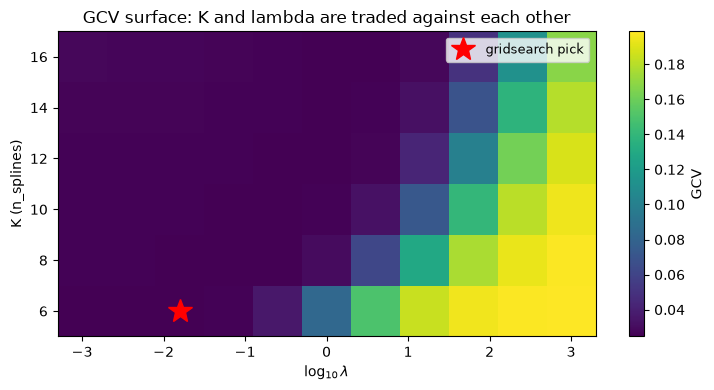

GCV range on the surface: 0.02468 .. 0.19878


In [24]:
# --- the GCV surface over (K, lambda) for a single smooth -------------------
Ks_surface = np.array([6, 8, 10, 12, 14, 16])
lams_surface = np.logspace(-3, 3, 11)
gcv_surface = np.zeros((Ks_surface.size, lams_surface.size))
for i, K_i in enumerate(Ks_surface):
    for j, lam_j in enumerate(lams_surface):
        gcv_surface[i, j] = LinGAM(n_splines=int(K_i), lam=float(lam_j), backend="eilers").fit(x, y).statistics_["GCV"]

m_surf = LinGAM(n_splines=12, backend="eilers").gridsearch(x, y, lam=lams_surface, n_splines=Ks_surface)
i_pick = int(np.flatnonzero(Ks_surface == m_surf.n_splines)[0])
j_pick = int(np.flatnonzero(np.isclose(lams_surface, m_surf.lam))[0])
print("gridsearch picked (K, lambda) =", (m_surf.n_splines, m_surf.lam), " with GCV =", round(m_surf.statistics_["GCV"], 7))
print("naive surface argmin          =", (Ks_surface[int(np.argmin(gcv_surface)) // lams_surface.size],
                                           lams_surface[int(np.argmin(gcv_surface)) % lams_surface.size]))

fig, ax = plt.subplots(figsize=(7.5, 4))
im = ax.pcolormesh(np.log10(lams_surface), Ks_surface, gcv_surface, cmap="viridis", shading="auto")
ax.plot(np.log10(m_surf.lam), m_surf.n_splines, "r*", ms=18, label="gridsearch pick")
ax.set(xlabel=r"$\log_{10}\lambda$", ylabel="K (n_splines)", title="GCV surface: K and lambda are traded against each other")
plt.colorbar(im, ax=ax, label="GCV")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"GCV range on the surface: {gcv_surface.min():.5f} .. {gcv_surface.max():.5f}")
assert (Ks_surface[int(np.argmin(gcv_surface)) // lams_surface.size], lams_surface[int(np.argmin(gcv_surface)) % lams_surface.size]) == (m_surf.n_splines, m_surf.lam)

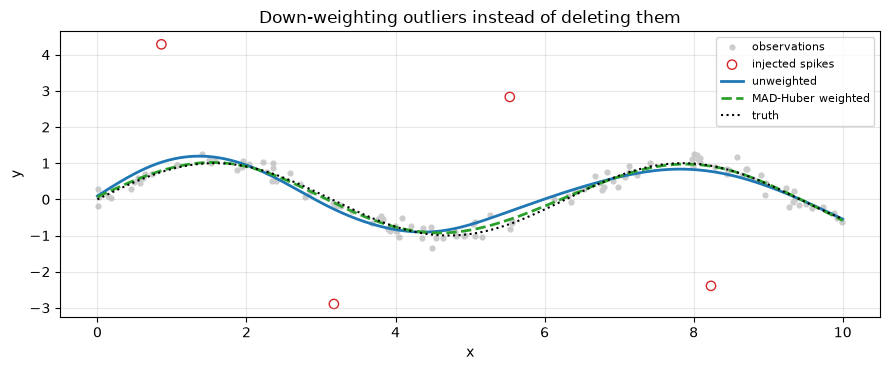

MAE on the clean points: unweighted 0.1805   weighted 0.1282   outliers deleted 0.1224
sigma: unweighted 0.6181   weighted 0.2559
weights at the spikes: [0.101 0.126 0.105 0.105]  (down-weighted observations: 18 of 120 )


In [25]:
# --- outliers and weights ---------------------------------------------------
rng_out = np.random.default_rng(5)
n_out = 120
x_out = np.sort(rng_out.uniform(0.0, 10.0, n_out))
truth_out = np.sin(x_out)
y_out = truth_out + rng_out.normal(0.0, 0.15, n_out)
spikes = np.array([12, 34, 67, 95])
y_out[spikes] += np.array([3.4, -3.1, 3.6, -3.3])
lam_out = np.logspace(-4, 3, 15)

plain = LinGAM(n_splines=16, backend="eilers").gridsearch(x_out, y_out, lam=lam_out)
resid = y_out - plain.predict(x_out)
mad = 1.4826 * np.median(np.abs(resid - np.median(resid)))
u = np.abs(resid) / mad
w = np.where(u <= 1.345, 1.0, 1.345 / u)
robust = LinGAM(n_splines=16, backend="eilers").gridsearch(x_out, y_out, lam=lam_out, weights=w)
clean = np.setdiff1d(np.arange(n_out), spikes)
dropped = LinGAM(n_splines=16, backend="eilers").gridsearch(x_out[clean], y_out[clean], lam=lam_out)

mae_clean = lambda m: float(np.mean(np.abs((y_out - m.predict(x_out))[clean])))
xg_out = np.linspace(0.0, 10.0, 400)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(x_out[clean], y_out[clean], s=12, color="0.8", label="observations")
ax.scatter(x_out[spikes], y_out[spikes], s=45, facecolors="none", edgecolors="C3", label="injected spikes")
ax.plot(xg_out, plain.predict(xg_out), "C0-", lw=2, label="unweighted")
ax.plot(xg_out, robust.predict(xg_out), "C2--", lw=2, label="MAD-Huber weighted")
ax.plot(xg_out, np.sin(xg_out), "k:", lw=1.5, label="truth")
ax.set(xlabel="x", ylabel="y", title="Down-weighting outliers instead of deleting them")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("MAE on the clean points: unweighted %.4f   weighted %.4f   outliers deleted %.4f"
      % (mae_clean(plain), mae_clean(robust), mae_clean(dropped)))
print("sigma: unweighted %.4f   weighted %.4f" % (plain.statistics_["scale"], robust.statistics_["scale"]))
print("weights at the spikes:", np.round(w[spikes], 3), " (down-weighted observations:", int((w < 1).sum()), "of", n_out, ")")

assert w[spikes].max() < 0.2
assert mae_clean(robust) < mae_clean(plain)
assert robust.statistics_["scale"] < plain.statistics_["scale"]

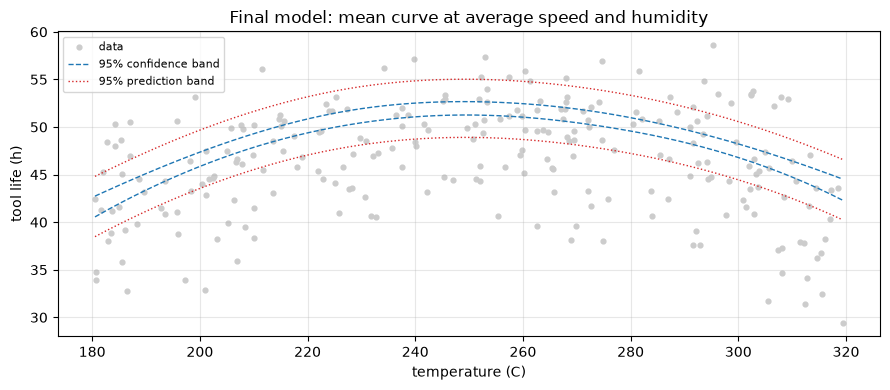

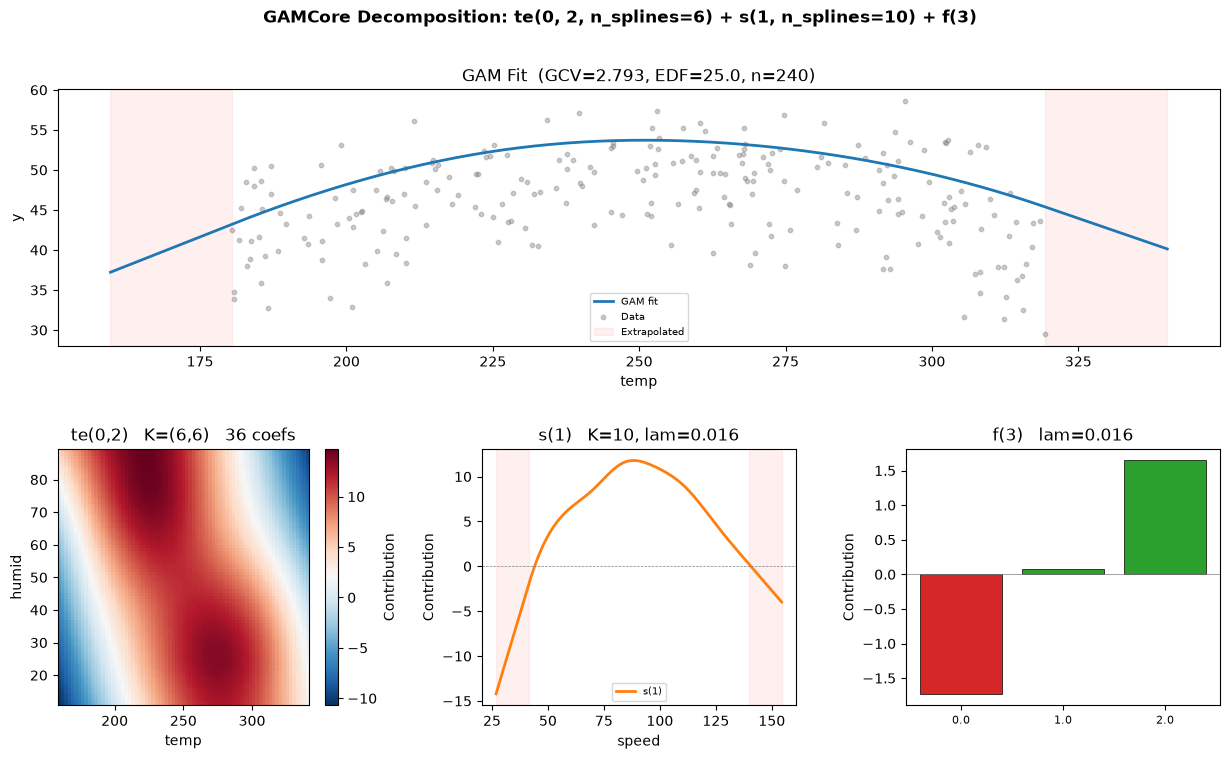

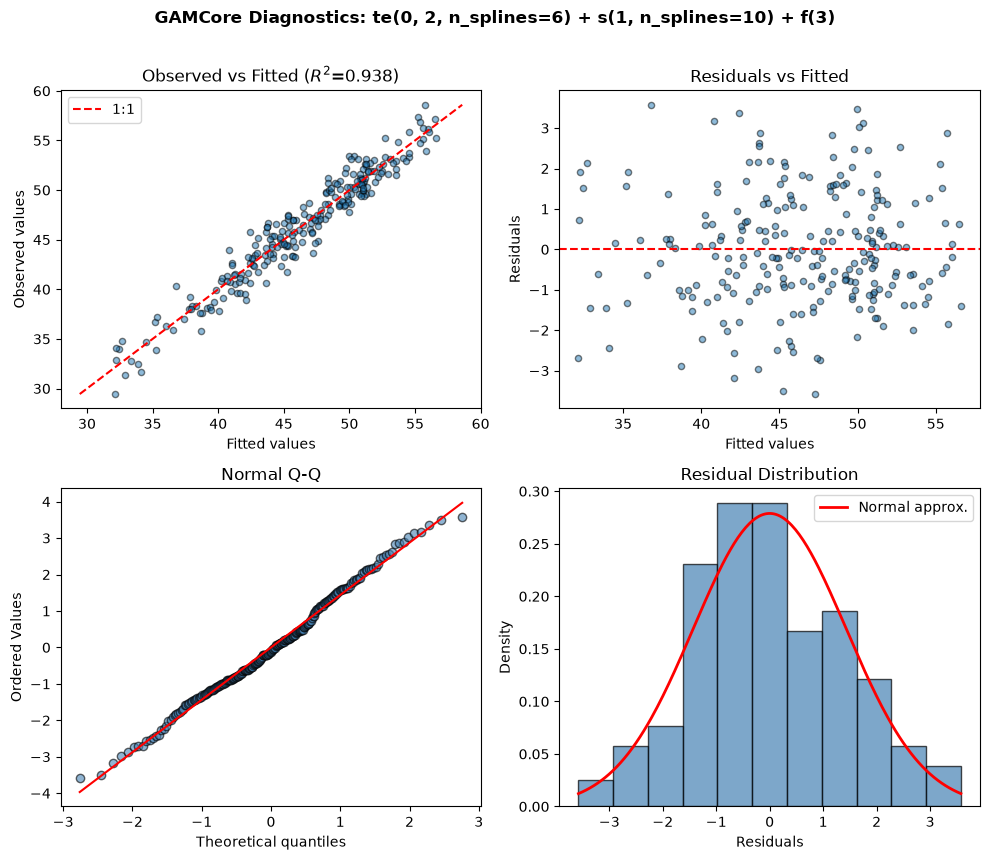

deviance explained: 0.9381
AIC / BIC         : 905.35 / 995.82
sigma             : 1.5083  (simulation: 1.6)
decomposition axes: 5 (at least 4 panels; the te() panel adds a colorbar axis)
diagnostics axes  : 4
predicted life quartiles: [32.14 42.69 46.92 50.75 56.61] h


In [26]:
# --- final report: predictions, intervals, decomposition, diagnostics -------
final = wf_fits["te(temp, humid)"]
slice_temp = np.linspace(temp.min(), temp.max(), 60)
report_pts = np.column_stack([slice_temp, np.full_like(slice_temp, speed.mean()),
                              np.full_like(slice_temp, humid.mean()), np.zeros_like(slice_temp)])
ci = final.confidence_intervals(report_pts, width=0.95)
pi = final.prediction_intervals(report_pts, width=0.95)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(temp, life, s=12, color="0.8", label="data")
ax.plot(slice_temp, ci[:, 0], "C0--", lw=1)
ax.plot(slice_temp, ci[:, 1], "C0--", lw=1, label="95% confidence band")
ax.plot(slice_temp, pi[:, 0], "C3:", lw=1)
ax.plot(slice_temp, pi[:, 1], "C3:", lw=1, label="95% prediction band")
ax.set(xlabel="temperature (C)", ylabel="tool life (h)",
       title="Final model: mean curve at average speed and humidity")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig_dec, axes_dec = final.plot_decomposition(X_wf, life, feature_names=feature_names)
plt.show()
fig_diag, axes_diag = final.plot_diagnostics(X_wf, life)
plt.show()

print("deviance explained:", round(final.deviance_explained(), 4))
print("AIC / BIC         :", round(final.aic(), 2), "/", round(final.bic(), 2))
print("sigma             :", round(final.statistics_["scale"], 4), " (simulation: 1.6)")
print("decomposition axes:", len(axes_dec),
      f"(at least {1 + final.n_terms} panels; the te() panel adds a colorbar axis)")
print("diagnostics axes  :", len(axes_diag))
print("predicted life quartiles:", np.round(np.quantile(final.predict(X_wf), [0, 0.25, 0.5, 0.75, 1.0]), 2), "h")

assert np.all(pi[:, 1] - pi[:, 0] > ci[:, 1] - ci[:, 0])
assert len(axes_dec) >= 1 + final.n_terms, "overall fit panel + one panel per term"
assert len(axes_diag) == 4
assert abs(final.statistics_["scale"] - 1.6) < 0.4

---
# Cheat sheet

## API map for the Eilers-Marx backend

| what you want | call |
|---|---|
| fit one smooth | `LinGAM(n_splines=12, lam=1.0)` (alias `GAM(..., backend='eilers')`) |
| tune it | `model.gridsearch(x, y)` — **never** expect `fit()` to choose `lam` |
| fit a formula | `GAMCore("s(0, n_splines=12) + te(0,1, n_splines=6) + f(2) + l(3)").gridsearch(X, y)` |
| control the search | `lam=`, `n_splines=`, `lam_grids=[...]`, `n_splines_grids=[...]`, `search_terms=`, `n_jobs=`, `gamma=` |
| constrain a shape | `constraint='mono_inc' \| 'mono_dec' \| 'convex' \| 'concave' \| 'periodic'` |
| machine-readable stats | `model.statistics_` (`edof`, `edof_per_coef`, `scale`, `cov`, `se`, `rss`, `GCV`, `null_deviance`) |
| effects | `partial_dependence(j, X)`, `plot_decomposition(X, y)` (shows 15% extrapolation shading) |
| predictions | `predict`, `confidence_intervals`, `prediction_intervals` |
| comparison | `GCV`, `aic()`, `bic()`, `deviance_explained()` |
| diagnostics | `plot_diagnostics(X, y)` |

## Eilers-Marx vs Wood at a glance

| | `backend='eilers'` | `backend='wood'` |
|---|---|---|
| basis | uniform cubic B-splines, `n_splines=K` | nine families (`tp`, `cr`, `ps`, `cc`, ...) |
| penalty | second differences `D2^T D2` (discrete) | exact curvature integrals or differences |
| choosing lambda | **GCV grid search, explicit** (`gridsearch`) | REML/GCV, continuous, inside `fit()` |
| `fit()` alone | uses the stored `lam` (default 1.0) | estimates lambda |
| criterion default | `gamma = 1.4` | `gamma = 1.0` (REML by default) |
| identifiability | implicit (redundant constant + ridge) | explicit sum-to-zero absorption |
| partial effects | level is shared with the intercept | centred at zero by construction |
| inference | frequentist covariance, intervals | `summary()`, Bayesian + sandwich covariance, Wood-2013 F-tests |
| `scale` | sigma | sigma squared |
| shape constraints | `mono_inc`/`mono_dec`/`convex`/`concave`/`periodic` | `periodic` only |
| factor terms | penalised ridge, lambda searched | unpenalised dummy coding |
| best at | speed, transparency, shape constraints | automatic inference, rich bases, p-values |

## Traps this notebook demonstrated

1. `fit()` does not tune `lam` — 4x better RMSE once `gridsearch()` was used.
2. `scale` is $\hat\sigma$; add `scale**2` for prediction variance.
3. The default grid shares one $\lambda$ across terms; independent grids do better
   (measured GCV 25.23 vs 25.57).
4. A second-difference penalty can only straighten a term (EDF floor 1, model floor 2).
5. The periodic wrap follows the **training range** — use data spanning exactly one
   period, or the seam leaks.
6. Shape constraints are a strong prior: `mono_inc` helped on a saturating curve,
   `convex` on a concave one tripled the error. They are also not available for `te()`.
7. `n_jobs` gave no speedup at notebook scale; the real win is the two-phase cache
   (measured ~6x over a naive refit loop).
8. No `summary()`, no p-values: compare models with GCV/AIC/BIC, holding gamma and
   weights fixed.

## Where to read more

* `docs/math/eilers.rst` — the full derivations behind Parts I-VI.
* `docs/constraints.rst` and `docs/gridsearch.rst` — the two features this backend
  owns.
* Eilers & Marx (1996), *Flexible smoothing with B-splines and penalties*,
  Statistical Science 11(2).
* S. N. Wood (2017), *Generalized Additive Models: An Introduction with R* (2nd
  ed.), CRC Press — chapters 4-5 for P-splines and basis construction.
* `examples/wood_backend_math_tutorial.ipynb` — the same tour for the other
  backend, with the REML/penalty-side derivations.

In [27]:
# --- closing invariant audit ------------------------------------------------
checks = {}

# 1. the recursion in Part II IS the library
checks["|hand de Boor - library|"] = float(np.abs(mine - library).max())

# 2. the penalty in Part III IS D2'D2
checks["|P - D2'D2|"] = float(np.abs(P_diff - D2_diff.T @ D2_diff).max())

# 3. the solver reproduces beta and EDF
checks["|beta_svd - beta_library|"] = float(np.abs(beta_svd - m_num.coef_).max())
checks["|EDF_svd - EDF_trace|"] = abs(edf_svd - edf_trace)

# 4. the criterion in Part V matches statistics_[GCV]
checks["|GCV hand - GCV stored|"] = abs(gcv_of(m_curves) - m_curves.statistics_["GCV"])

# 5. the grid search found the surface minimum
checks["|GCV surface argmin - pick|"] = abs(float(gcv_surface.min()) - m_surf.statistics_["GCV"])

# 6. the constrained fits respect their constraints
checks["mono_inc min step (< 0 is bad)"] = min_delta(mono)
checks["convex min 2nd diff (< 0 is bad)"] = d2_of(convex_cost)
checks["periodic seam gap (exact period)"] = gap(m_exact)

print(f"{'check':>34} {'value':>14}")
for name, value in checks.items():
    print(f"{name:>34} {value:14.3e}")

assert abs(checks["|hand de Boor - library|"]) == 0.0
assert abs(checks["|P - D2'D2|"]) == 0.0
assert abs(checks["|beta_svd - beta_library|"]) < 1e-12
assert abs(checks["|EDF_svd - EDF_trace|"]) < 1e-6
assert abs(checks["|GCV hand - GCV stored|"]) < 1e-12
assert abs(checks["|GCV surface argmin - pick|"]) < 1e-9
assert checks["mono_inc min step (< 0 is bad)"] > -1e-9
assert checks["convex min 2nd diff (< 0 is bad)"] > -1e-9
assert checks["periodic seam gap (exact period)"] < 1e-9
print("\nAll invariant checks passed. The markdown and the code agree.")

                             check          value
          |hand de Boor - library|      0.000e+00
                       |P - D2'D2|      0.000e+00
         |beta_svd - beta_library|      0.000e+00
             |EDF_svd - EDF_trace|      8.012e-08
           |GCV hand - GCV stored|      0.000e+00
       |GCV surface argmin - pick|      0.000e+00
    mono_inc min step (< 0 is bad)     -7.117e-12
  convex min 2nd diff (< 0 is bad)     -3.252e-12
  periodic seam gap (exact period)      0.000e+00

All invariant checks passed. The markdown and the code agree.
